# CGGD-SlotLoc — replacing the count-only bin classifier with a shared slot-attention head for counting *and* location

## Why this version exists

`proper_CGGD_Florence2_Generative.ipynb` (v6) got the data pipeline right (baseline-aligned
splits, exact `QUES2CATS`, exact LoRA config, unsmoothed BLEU) but its own diagnostic cell
(Section 11) showed the counting-specific architecture **losing to doing nothing**:

```
classifier_acc = 0.733   generation_acc = 0.895   gap = +0.162
```

All that machinery -- `CountingResampler` -> `AuxCountHead` (mean+max pool -> one vector -> 7-way
softmax) -> `ordinal_soft_loss` -> `CountConditioner` fusion -- was worse than the plain LM just
generating a digit. And `location` had **no dedicated mechanism at all**: `compute_embeds` gated
the one grounding token off for every non-counting row, with a comment admitting it caused a
Location regression in an earlier run.

Two root causes, one fix:

1. **Mean+max pooling across the 16 resampler queries throws away *which* query found *what*.**
   That's exactly the information a counting head needs (how many distinct things were found) and
   a location head needs (where each one was). Collapsing to one global vector before reading
   anything out destroys it.
2. **Location never got a readout path.** The resampler already computes `attn_weights` -- a
   spatial attention map per query over patch tokens -- and the old code only fed it to the
   diversity/entropy losses. That map *is* a location signal; it was being thrown away.

This version keeps the resampler / LoRA / generative-decode-as-primary-answer design (all of that
was sound) and replaces the *readout head* with a slot-attention-style module:

| Concept | v6 (old) | v7 -- this notebook |
|---|---|---|
| Pooling | blind mean+max over all 16 queries | per-slot occupancy probability; occupancy-*weighted* pooling |
| Count signal | single global 7-way softmax from the pooled blob | soft cardinality = sum of per-slot occupancy, **plus** a bin classifier fed by occupancy-weighted features (both trained) |
| Location signal | none -- grounding token zeroed on location rows | per-slot soft centroid (soft-argmax of that slot's own attention map over the patch grid), occupancy-weighted into one centroid, classified into a closed-set location vocabulary built from the training answers |
| Grounding token | one token, count-only content, presence-gated off for location rows | one token, *content*-gated per row (count content / location content / plain), always present |
| Fusion default | classifier overrides generation when confident | **off by default for both tasks** until re-measured against generation with this new head (see Section 11) -- the old default was set when the old head was already known to be worse |

Batch sampling is also extended: the old `CountAwareBatchSampler` only guaranteed a counting
example per batch; `GuidedBatchSampler` alternates guaranteeing a counting example and a location
example (and both, when `batch_size >= 3`), so the location head — which was getting essentially
no concentrated training signal before — actually sees enough location rows per batch to learn.


## 0. Baseline provenance

This notebook targets **`src/florence2_64_r16.ipynb`** from
[gauravparajuli/ImageCLEFmed-MEDVQA-GI-2025-Task1](https://github.com/gauravparajuli/ImageCLEFmed-MEDVQA-GI-2025-Task1)
-- the variant Table 4 of the paper attributes the best overall numbers to (BLEU 0.21, ROUGE1 0.87,
ROUGE2 0.12, ROUGEL 0.86, METEOR 0.48 on the public test set).

**Sourcing note, corrected from an earlier version of this notebook:** GitHub's `robots.txt` blocks
a plain fetcher from reading raw `.ipynb` files, but `api.github.com` and `codeload.github.com` are
not blocked -- this notebook's hyperparameters were pulled by downloading the actual repo as a zip
via `codeload.github.com` and reading `src/florence2_64_r16.ipynb`,
`src/florence2_hyperparameter.ipynb`, and both `submission_task1*.py` scripts directly, cell by
cell. An earlier version of this notebook instead transcribed hyperparameters from the paper's
Section 4.2.1 prose, which turned out to describe a **different** notebook --
`archive/florence2_4_r16.ipynb` (effective batch 4, LR 2.4e-5, active `EarlyStoppingCallback`) --
not the one actually referenced by Table 4. Both `submission_task1.py` and
`submission_task1_catwise.py` hardcode `adapter_model_id = "gauravparajuli/florence2_4_r16"`, which
is a real, unresolved inconsistency in the source repo itself (Table 4 labels the reported numbers
"Florence2_64_r16" while the scripts that would have generated those numbers point at a
differently-configured checkpoint). This notebook targets `florence2_64_r16` per an explicit
decision to do so, since the 4_r16 recipe was already tried and gave no improvement.

**Verified real config for `florence2_64_r16.ipynb`** (not derived, read directly from the
notebook's cells): per-device batch 4, gradient accumulation 16 (effective batch 64), learning
rate 9.6e-5 used directly (a `scaled_learning_rate = BASE_LEARNING_RATE * sqrt(effective_batch/20)`
variable is computed but never passed to `TrainingArguments` -- dead code in the real notebook),
weight decay 0.07, 5 epochs, **no active early stopping** (`EarlyStoppingCallback` is commented
out; `load_best_model_at_end=True` with the default `eval_loss` metric picks the best checkpoint
after all 5 epochs run, it doesn't stop training early), no `lr_scheduler_type`/warmup set (HF
Trainer defaults apply: linear decay, zero warmup), `fp16=True`, and `LoraConfig` applied to the
**whole** Florence-2 model (`model = get_peft_model(model, lora_config)`), not just the language
model. All of this is now implemented exactly in Sections 5-7 below, with one disclosed deviation:
we keep `bf16` instead of `fp16` (see Section 5's note) since matching `fp16` in our custom
training loop would mean hand-implementing `GradScaler`, which HF `Trainer` gets for free.

What this notebook adds on top of the (now correctly reproduced) baseline: a slot-attention
counting+location head, evaluated against the baseline's own faithfully-reproduced numbers in
Section 10.


## 0.5. Lessons carried over from real runs of this codebase

Two real runs have now happened: the predecessor notebook (`CGGD-Gen`) end-to-end on a local
machine, and this notebook's first training attempt, which crashed immediately. Five concrete
problems surfaced, all fixed below (search each keyword to find the fix):

1. **`val_aux` was dead flat for all 5 epochs** (0.2161 -> 0.2086 -> 0.2053 -> 0.2024 -> 0.2029)
   under a single shared LR for both the pretrained LoRA backbone and the from-scratch aux
   modules. A confusion matrix then showed the head had collapsed onto the majority class: 56% of
   predictions landed in bin 0 alone, and bins 3-6 had 0% recall. **Fix**: `trainable_parameter_groups()`
   splits LoRA params from aux params into separate optimizer groups, aux getting a 10x higher LR
   (Section 7). This alone doesn't guarantee the SlotLoc head won't also collapse -- run
   `count_confusion_matrix` / `location_confusion_summary` (Section 11) and actually look before
   trusting any aggregate accuracy number.
2. **Fusion barely ever triggered and didn't move the needle**: even at the best confidence
   threshold found by the sweep (0.95), only 10% of counting questions got fused, and exact-match
   accuracy was statistically flat across every threshold from 0.8 upward (93.8% -> 94.4% ->
   94.4% -> 94.5%). This independently confirms the default-fusion-off design decision already
   built into this notebook (Section 4) -- free generation was already doing the work.
3. **The comparison-table generation call wasn't apples-to-apples with the baseline**: an earlier
   run capped `max_new_tokens`, which the baseline's own `submission_task1_catwise.py` never does
   (it relies on Florence-2's default `max_length=20`). Capping it makes the head-to-head unfair in
   whichever direction the cap happens to help or hurt. **Fix**: `generate_predictions` (Section
   5.5) defaults to no `max_new_tokens` override for the comparison table; short bounded caps are
   still used in the diagnostic/qualitative sections where only a short numeric or location answer
   is ever expected and speed matters more than exact baseline parity.
4. **~14000s/epoch (~3.9h) on a local Windows GPU with `num_workers=0`**, meaning image decode and
   processor preprocessing ran single-threaded on the CPU, unoverlapped with the GPU step -- 5
   epochs took ~19.4h total, and that run never even reached the LoRA-only control to get a real
   ablation number. **Fix**: `DataLoader` calls now accept `num_workers`/`pin_memory` (Section
   6/7), and `collate_fn` is wrapped with `functools.partial` instead of a `lambda` specifically so
   `num_workers > 0` doesn't crash -- lambdas aren't picklable under Windows' spawn-based
   multiprocessing, so the old `collate_fn=lambda b: collate_fn(b, processor)` pattern silently
   capped you at `num_workers=0` forever. **This notebook now runs the LoRA-only control (Section
   6) before the full CGGD-SlotLoc training (Section 7)**, not after -- it has no aux
   heads/resampler and trains faster, so you're guaranteed a comparison number even if the full run
   doesn't finish. CGGD-SlotLoc has *more* aux compute per step than CGGD-Gen did (two heads
   instead of one, plus the conditioner and readout), so budget for it to be slower per epoch, not
   faster, even with these fixes.
5. **First actual training attempt of this notebook crashed immediately** with
   `ValueError: Patch token count 577 isn't a perfect square`. Florence-2-base's vision tower emits
   `grid_side**2 + 1` patch tokens (577 = 24*24 + 1), not a bare perfect square -- it prepends one
   global/CLS-style token, the same layout CLIP ViT-L/14 uses. The naive `sqrt(N)` check in
   `_resolve_grid_side` had no fallback for this. **Fix**: `_resolve_grid_side` now also tries
   `sqrt(N - 1)`, and when that's the perfect square, `soft_centroid` drops token index 0 before
   the row/col soft-argmax and renormalizes the remaining spatial attention mass to sum to 1 again
   (Section 4) -- otherwise the centroid would be silently pulled toward wherever the global
   token's dropped attention mass implied, i.e. nowhere spatially real.
6. **A completed real run of Section 6 (the `florence2_4_r16`-recipe LoRA-only control: effective
   batch 4, LR 2.4e-5, active early stopping) gave no improvement** over earlier attempts, and
   comparison against the actual repo source (see Section 0) showed why that recipe was never
   quite the right target in the first place -- it's a real notebook in the repo, but not the one
   Table 4 attributes the paper's headline numbers to. **Fix**: this notebook now implements the
   verified `florence2_64_r16` recipe throughout Sections 5-7 -- effective batch 64, LR 9.6e-5,
   weight_decay 0.07, linear scheduler with zero warmup for the faithful control, LoRA applied to
   the whole model, and no active early stopping in Section 6 (matching the real code exactly).

The real run's actual numbers, for calibration: overall test BLEU 0.184 (vs. the baseline paper's
0.21), with `choice(single)`/`choice(multiple)`/`location` ROUGE1 notably below the paper's
(0.69/0.61/0.69 vs. 0.80/0.84/0.84). Whether that gap comes from the CGGD machinery, from natural
run-to-run variance, or from something else entirely couldn't be determined because the LoRA-only
control never finished (lesson 4 above) -- treat closing that specific gap as an open question
this notebook is set up to actually answer, not a known regression to explain away.


In [1]:

import json, math, random, re, time, functools, gc
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset

import matplotlib.pyplot as plt

torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_ID = "microsoft/Florence-2-base-ft"
PROJ_DIM = 768
NUM_QUERIES = 16
NUM_BINS = 7                       # count bins 0..5 exact, bin 6 = "6+" (ours; unrelated to baseline)
LOCATION_MAX_CLASSES = 12          # closed-set cap for the location classifier head
LOCATION_MIN_FREQ = 8              # an answer needs >= this many occurrences in hf_train to get its own class
CKPT_DIR = Path("checkpoints")
CKPT_DIR.mkdir(exist_ok=True)
RESULTS_DIR = Path("eval_results")
RESULTS_DIR.mkdir(exist_ok=True)
MODEL_DTYPE = torch.bfloat16

# Baseline's exact train/val split recipe (src/florence2_64_r16.ipynb)
TRAIN_SOURCE_DATASET = "SimulaMet-HOST/Kvasir-VQA"
TRAIN_SOURCE_SPLIT = "raw"
SPLIT_SEED = 7
SPLIT_TEST_SIZE = 0.1

# Baseline's exact reported-test-score source (submission_task1.py / submission_task1_catwise.py)
TEST_DATASET = "SimulaMet/Kvasir-VQA-test"
TEST_SPLIT = "validation"

# ---------------------------------------------------------------------------
# Baseline hyperparameters, VERIFIED against the actual source code -- fetched
# via GitHub's REST/codeload API (api.github.com and codeload.github.com are
# reachable even though github.com's raw-file robots.txt blocks a plain
# fetcher) and read directly from src/florence2_64_r16.ipynb and
# src/florence2_hyperparameter.ipynb, not inferred from the paper's prose.
#
# The paper's Section 4.2.1 methodology text (LR divided by 4 for gradient
# explosion, then sqrt-rescaled, active early stopping) turned out to describe
# a DIFFERENT notebook -- archive/florence2_4_r16.ipynb (effective batch 4,
# LR 2.4e-5, EarlyStoppingCallback active) -- not the one we're targeting.
# florence2_64_r16.ipynb, confirmed as the source of Table 4's reported
# numbers, actually does something simpler: it computes a sqrt-scaled LR
# (`scaled_learning_rate`) but NEVER USES IT -- `TrainingArguments(learning_rate=...)`
# is passed the raw `BASE_LEARNING_RATE` directly, and `EarlyStoppingCallback`
# is commented out entirely, so training just runs all 5 epochs unconditionally
# and keeps the best-by-eval-loss checkpoint via `load_best_model_at_end=True`.
# ---------------------------------------------------------------------------

# Optuna search result (florence2_hyperparameter.ipynb, n_trials=50 -- the paper
# says 100, the executed code says 50; study.best_params, verified from the
# notebook's own saved cell output):
SEARCHED_LR = 9.596461243144801e-05
SEARCHED_PER_DEVICE_BATCH = 2
SEARCHED_GRAD_ACCUM_STEPS = 1
SEARCHED_WEIGHT_DECAY = 0.07115933746212984
SEARCHED_LORA_R = 16
SEARCHED_LORA_ALPHA = 32
SEARCHED_LORA_DROPOUT = 0.054778160858588026

# src/florence2_64_r16.ipynb's ACTUAL executed training config (cell 12/13,
# read verbatim -- not derived):
#   PER_DEVICE_TRAIN_BATCH_SIZE = 4
#   GRADIENT_ACCUMULATION_STEPS = 16
#   BASE_LEARNING_RATE = 9.6e-5          # used directly as `learning_rate=`
#   scaled_learning_rate = BASE_LEARNING_RATE * sqrt(effective_batch/20)  # computed, NEVER used -- dead code
#   WEIGHT_DECAY = 0.07
#   NUM_EPOCHS = 5
#   fp16=True                             # we deliberately keep bf16 instead -- see Section 5
#   load_best_model_at_end=True, callbacks=[] (EarlyStoppingCallback commented out -- inactive)
#   no lr_scheduler_type / warmup set -> HF Trainer defaults: linear decay, zero warmup
BASELINE_LR = 9.6e-5
BASELINE_PER_DEVICE_BATCH = 4
BASELINE_GRAD_ACCUM_STEPS = 16  # effective batch 64
BASELINE_WEIGHT_DECAY = 0.07
BASELINE_EPOCHS = 5
BASELINE_PATIENCE = None  # matches the real notebook: no active early stopping, always runs all 5 epochs
BASELINE_LR_SCHEDULER = "linear"
BASELINE_WARMUP_STEPS = 0

print(f"BASELINE_LR = {BASELINE_LR:.4e}  (used directly -- the real notebook's sqrt-scaled variant is dead code)")
print(f"BASELINE_PER_DEVICE_BATCH={BASELINE_PER_DEVICE_BATCH}  BASELINE_GRAD_ACCUM_STEPS={BASELINE_GRAD_ACCUM_STEPS}  "
      f"effective_batch={BASELINE_PER_DEVICE_BATCH * BASELINE_GRAD_ACCUM_STEPS}")
print(f"BASELINE_WEIGHT_DECAY={BASELINE_WEIGHT_DECAY}  BASELINE_LR_SCHEDULER={BASELINE_LR_SCHEDULER} "
      f"(warmup_steps={BASELINE_WARMUP_STEPS})")
print(f"BASELINE_EPOCHS={BASELINE_EPOCHS}  BASELINE_PATIENCE={BASELINE_PATIENCE} (None = no early stopping, matches real code)")

RUN_NAME = "cggd_slotloc"
NOTEBOOK_VERSION = ("slot-attention readout shared by counting and location; occupancy-"
                     "weighted pooling replaces blind mean+max; per-slot soft centroid gives "
                     "location a real grounding signal for the first time; content-gated (not "
                     "presence-gated) single conditioning token; count/location fusion default "
                     "OFF pending re-measurement against generation with this head; "
                     "GuidedBatchSampler covers both minority classes per batch")

# Baseline's exact category names (submission_task1_catwise.py)
QUESTION_TYPES = ["yes_no", "choice(single)", "choice(multiple)", "choice(color)", "location", "numerical_count"]
COUNT_TYPE = "numerical_count"
LOCATION_TYPE = "location"

def log_gpu_memory(tag=""):
    """Prints allocated/reserved CUDA memory. Call before/after each heavy training section --
    a silent, no-traceback kernel crash is a classic symptom of a Windows/CUDA-driver-level OOM
    (PyTorch's own OutOfMemoryError doesn't always get raised cleanly on every driver version), so
    watching this trend across cells is one of the few ways to catch it before it kills the kernel."""
    if DEVICE != "cuda":
        print(f"[gpu_mem{' ' + tag if tag else ''}] no CUDA device")
        return
    alloc = torch.cuda.memory_allocated() / 1e9
    reserved = torch.cuda.memory_reserved() / 1e9
    peak = torch.cuda.max_memory_allocated() / 1e9
    print(f"[gpu_mem{' ' + tag if tag else ''}] allocated={alloc:.2f}GB  reserved={reserved:.2f}GB  peak_allocated={peak:.2f}GB")


def release_gpu_memory(*objs):
    """Explicitly drop references and force-release CUDA memory. PyTorch's caching allocator
    doesn't always return memory to the OS/driver promptly just because Python objects went out of
    scope -- calling this between Section 6 (LoRA-only) and Section 7 (CGGD-SlotLoc) matters
    because both sections build their own optimizer/scheduler/DataLoader objects on top of the
    SAME shared base_model, and leftover CUDA allocations from one can compound with the next on a
    memory-constrained GPU."""
    for o in objs:
        del o
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


print(f"notebook_version={NOTEBOOK_VERSION}")
print(f"device={DEVICE}")
log_gpu_memory("startup")


c:\Users\Shrinivas\Desktop\Improvement-on-baseline\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


BASELINE_LR = 9.6000e-05  (used directly -- the real notebook's sqrt-scaled variant is dead code)
BASELINE_PER_DEVICE_BATCH=4  BASELINE_GRAD_ACCUM_STEPS=16  effective_batch=64
BASELINE_WEIGHT_DECAY=0.07  BASELINE_LR_SCHEDULER=linear (warmup_steps=0)
BASELINE_EPOCHS=5  BASELINE_PATIENCE=None (None = no early stopping, matches real code)
notebook_version=slot-attention readout shared by counting and location; occupancy-weighted pooling replaces blind mean+max; per-slot soft centroid gives location a real grounding signal for the first time; content-gated (not presence-gated) single conditioning token; count/location fusion default OFF pending re-measurement against generation with this head; GuidedBatchSampler covers both minority classes per batch
device=cuda
[gpu_mem startup] allocated=0.00GB  reserved=0.00GB  peak_allocated=0.00GB


## 1. Question category — the baseline's exact dictionary, not a heuristic

Unchanged from v6 -- copied verbatim from `submission_task1_catwise.py`.

In [2]:

QUES2CATS = {
    'Have all polyps been removed?': 'yes_no',
    'Is this finding easy to detect?': 'yes_no',
    'Is there a green/black box artefact?': 'yes_no',
    'Is there text?': 'yes_no',
    'Does this image contain any finding?': 'yes_no',
    'What type of polyp is present?': 'choice(single)',
    'What type of procedure is the image taken from?': 'choice(single)',
    'What is the size of the polyp?': 'choice(single)',
    'Are there any abnormalities in the image? Check all that are present.': 'choice(multiple)',
    'Are there +any anatomical landmarks in the image? Check all that are present.': 'choice(multiple)',
    'Are there any instruments in the image? Check all that are present.': 'choice(multiple)',
    'What color is the abnormality? If more than one separate with ;': 'choice(color)',
    'What color is the anatomical landmark? If more than one separate with ;': 'choice(color)',
    'Where in the image is the instrument?': 'location',
    'Where in the image is the abnormality?': 'location',
    'Where in the image is the anatomical landmark?': 'location',
    'How many findings are present?': 'numerical_count',
    'How many polyps are in the image?': 'numerical_count',
    'How many instrumnets are in the image?': 'numerical_count',  # sic -- baseline's exact typo, kept verbatim
}

_unmapped_questions_seen = set()

def classify_question_type(question: str) -> str:
    q = question.strip()
    if q in QUES2CATS:
        return QUES2CATS[q]
    _unmapped_questions_seen.add(q)
    return "unmapped"


def to_bin(n: int) -> int:
    return min(n, NUM_BINS - 1)


## 2. Data loading — the exact HuggingFace datasets and split the baseline used

Unchanged from v6.

In [3]:

print(f"Loading {TRAIN_SOURCE_DATASET} split={TRAIN_SOURCE_SPLIT} ...")
raw_ds = load_dataset(TRAIN_SOURCE_DATASET)[TRAIN_SOURCE_SPLIT]
print(f"  {len(raw_ds)} rows total")

_split = raw_ds.train_test_split(test_size=SPLIT_TEST_SIZE, seed=SPLIT_SEED)
hf_train, hf_val = _split["train"], _split["test"]
print(f"  train={len(hf_train)}  val={len(hf_val)}  (seed={SPLIT_SEED}, test_size={SPLIT_TEST_SIZE}, matches baseline exactly)")

print(f"Loading {TEST_DATASET} split={TEST_SPLIT} (the baseline's actual reported-score source) ...")
hf_test = load_dataset(TEST_DATASET, split=TEST_SPLIT)
print(f"  test={len(hf_test)}")


Loading SimulaMet-HOST/Kvasir-VQA split=raw ...
  58849 rows total
  train=52964  val=5885  (seed=7, test_size=0.1, matches baseline exactly)
Loading SimulaMet/Kvasir-VQA-test split=validation (the baseline's actual reported-score source) ...
  test=1384


## 2.5. Location vocabulary — built from `hf_train` only, same spirit as the count-bin sentinel

Location answers in Kvasir-VQA are free text, so a closed-set classifier head needs a fixed label
space. Build one from the training split's actual answer frequencies (never from val/test — that
would leak). Answers that don't make the cut get `location_bin = -100`, exactly like an
unparseable count answer today: the classification head simply isn't supervised on that row, but
the generative LM loss still trains on it normally, so nothing is thrown away — it just isn't
double-covered by the closed-set head.


In [4]:

def build_location_vocab(hf_dataset, min_freq=LOCATION_MIN_FREQ, max_classes=LOCATION_MAX_CLASSES):
    c = Counter()
    for rec in hf_dataset:
        if classify_question_type(rec["question"]) == LOCATION_TYPE:
            c[rec["answer"].strip().lower()] += 1
    vocab = [a for a, n in c.most_common(max_classes) if n >= min_freq]
    covered = sum(n for a, n in c.items() if a in vocab)
    total = sum(c.values())
    print(f"Location vocab ({len(vocab)} classes, min_freq={min_freq}, max_classes={max_classes}):")
    for a in vocab:
        print(f"    {a!r}  (n={c[a]})")
    print(f"Closed-set vocab covers {covered}/{total} ({covered / max(total, 1):.1%}) of location "
          f"answers in hf_train. The remainder trains the LM head normally but is excluded from "
          f"the closed-set location classifier loss (location_bin = -100).")
    return vocab


def to_location_bin(answer: str, vocab):
    a = answer.strip().lower()
    return vocab.index(a) if a in vocab else -100


LOCATION_VOCAB = build_location_vocab(hf_train)
NUM_LOCATION_CLASSES = max(len(LOCATION_VOCAB), 1)


Location vocab (12 classes, min_freq=8, max_classes=12):
    'none'  (n=3089)
    'center; center-left; center-right; lower-center; lower-left; lower-right; upper-center; upper-left; upper-right'  (n=1607)
    'center; center-left; upper-center; upper-left'  (n=174)
    'center; center-left; center-right; lower-center; lower-right; upper-center; upper-left; upper-right'  (n=162)
    'center; upper-center'  (n=160)
    'center; center-right; lower-center; lower-right'  (n=118)
    'center; center-right; upper-center; upper-right'  (n=97)
    'center'  (n=96)
    'lower-center; lower-right'  (n=91)
    'center; lower-center'  (n=91)
    'center; center-left; lower-center; lower-left; upper-center; upper-left'  (n=81)
    'center; center-left; lower-center; lower-left'  (n=60)
Closed-set vocab covers 5826/7565 (77.0%) of location answers in hf_train. The remainder trains the LM head normally but is excluded from the closed-set location classifier loss (location_bin = -100).


## 3. Dataset wrapper, extended for location, and a batch sampler that guards both minority tasks

`KvasirVQADataset` now carries `location_bins` alongside `count_bins`. `GuidedBatchSampler`
replaces `CountAwareBatchSampler`: it still guarantees a counting example every batch, and now
also guarantees a location example, alternating which task gets the single guaranteed slot when
`batch_size` is too small (2) to fit both a dedicated count slot and a dedicated location slot,
and giving both a dedicated slot whenever `batch_size >= 3`.


In [5]:

class KvasirVQADataset(Dataset):
    """Wraps a HuggingFace Dataset (hf_train / hf_val / hf_test) with question-type labels from
    the baseline's exact QUES2CATS dict, a count_bin field, and (new) a location_bin field for
    the closed-set location classifier."""
    def __init__(self, hf_dataset, location_vocab, name="dataset"):
        self.ds = hf_dataset
        self.location_vocab = location_vocab
        self.qtypes = []
        self.count_bins = []
        self.location_bins = []
        type_counts = Counter()
        for rec in self.ds:
            q, a = rec["question"], rec["answer"]
            qtype = classify_question_type(q)
            count_bin = to_bin(int(a.strip())) if (qtype == COUNT_TYPE and re.fullmatch(r"\d+", a.strip())) else -100
            location_bin = to_location_bin(a, location_vocab) if qtype == LOCATION_TYPE else -100
            self.qtypes.append(qtype)
            self.count_bins.append(count_bin)
            self.location_bins.append(location_bin)
            type_counts[qtype] += 1
        n_loc_total = sum(1 for t in self.qtypes if t == LOCATION_TYPE)
        n_loc_covered = sum(1 for b in self.location_bins if b != -100)
        print(f"[{name}] {len(self.ds)} rows -- question-type distribution: {dict(type_counts)}")
        print(f"[{name}] location rows: {n_loc_total}, covered by closed-set vocab: {n_loc_covered} "
              f"({n_loc_covered / max(n_loc_total, 1):.1%})")
        if _unmapped_questions_seen:
            print(f"  WARNING: {len(_unmapped_questions_seen)} question string(s) not in the "
                  f"baseline's QUES2CATS dict were seen while building '{name}': "
                  f"{sorted(_unmapped_questions_seen)[:5]}{'...' if len(_unmapped_questions_seen) > 5 else ''}")

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        rec = self.ds[idx]
        image = rec["image"]
        if image.mode != "RGB":
            image = image.convert("RGB")
        return {"image": image, "question": rec["question"], "answer": rec["answer"],
                "question_type": self.qtypes[idx], "count_bin": self.count_bins[idx],
                "location_bin": self.location_bins[idx], "img_id": rec.get("img_id", idx)}

    def type_distribution(self):
        return Counter(self.qtypes)

    def count_bin_distribution(self):
        return Counter(b for b in self.count_bins if b != -100)

    def location_bin_distribution(self):
        return Counter(b for b in self.location_bins if b != -100)

    def count_class_weights(self, num_bins=NUM_BINS, alpha=0.180, tau_floor=0.335, tau_cap=3.257):
        # Optuna TPE calibrated weights (tune_cggd_hyperparameters.py):
        # Replaces raw inverse-sqrt (32x gap) with power-smoothing (alpha=0.180) and floor (0.335)
        # to protect majority classes (bin 0/1) from gradient starvation while providing minority recall.
        dist = self.count_bin_distribution()
        counts = torch.tensor([dist.get(b, 0) for b in range(num_bins)], dtype=torch.float)
        counts = torch.clamp(counts, min=1.0)
        med = torch.median(counts)
        w = torch.pow(med / counts, alpha)
        w = w / w.mean()
        w = torch.clamp(w, min=tau_floor, max=tau_cap)
        return w / w.mean()

    def location_class_weights(self, num_classes=NUM_LOCATION_CLASSES, alpha=0.294, tau_floor=0.335, tau_cap=3.257):
        # Optuna TPE calibrated location weights:
        if num_classes == 0:
            return None
        dist = self.location_bin_distribution()
        counts = torch.tensor([dist.get(b, 0) for b in range(num_classes)], dtype=torch.float)
        counts = torch.clamp(counts, min=1.0)
        med = torch.median(counts)
        w = torch.pow(med / counts, alpha)
        w = w / w.mean()
        w = torch.clamp(w, min=tau_floor, max=tau_cap)
        return w / w.mean()


def collate_fn(batch, processor):
    images = [b["image"] for b in batch]
    questions = [b["question"] for b in batch]
    answers = [b["answer"] for b in batch]
    qtypes = [b["question_type"] for b in batch]
    count_bins = torch.tensor([b["count_bin"] for b in batch], dtype=torch.long)
    location_bins = torch.tensor([b["location_bin"] for b in batch], dtype=torch.long)
    enc = processor(text=questions, images=images, return_tensors="pt", padding=True)
    with processor.tokenizer.as_target_tokenizer():
        labels = processor.tokenizer(answers, return_tensors="pt", padding=True).input_ids
    labels[labels == processor.tokenizer.pad_token_id] = -100
    return {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"],
            "pixel_values": enc["pixel_values"], "labels": labels,
            "count_labels": count_bins, "location_labels": location_bins,
            "question_types": qtypes}


class GuidedBatchSampler(torch.utils.data.Sampler):
    """Guarantees every batch has >=1 counting example AND (task-coverage permitting) >=1
    location example. With batch_size==2 there's only room for one guaranteed slot, so the
    guarantee alternates between the two tasks per batch; with batch_size>=3 both get a dedicated
    slot every batch. Deliberately NOT applied to the LoRA-only control -- that model has no
    auxiliary heads to benefit, and using a different sampler there would confound the ablation."""
    def __init__(self, dataset, batch_size, seed=42):
        self.batch_size = batch_size
        self.count_indices = [i for i, b in enumerate(dataset.count_bins) if b != -100]
        self.location_indices = [i for i, t in enumerate(dataset.qtypes) if t == LOCATION_TYPE]
        self.other_indices = [i for i, t in enumerate(dataset.qtypes) if t not in (COUNT_TYPE, LOCATION_TYPE)]
        self.n_batches = math.ceil(len(dataset) / batch_size)
        self.rng = random.Random(seed)
        if not self.count_indices:
            print("[GuidedBatchSampler] WARNING: no counting-question examples found.")
        if not self.location_indices:
            print("[GuidedBatchSampler] WARNING: no location-question examples found.")

    def __iter__(self):
        count_pool = self.count_indices.copy() or list(range(1))
        if self.count_indices:
            self.rng.shuffle(count_pool)
        loc_pool = self.location_indices.copy()
        if loc_pool:
            self.rng.shuffle(loc_pool)
        other_pool = (self.other_indices.copy() if self.other_indices
                      else (self.count_indices + self.location_indices).copy())
        self.rng.shuffle(other_pool)
        cp = lp = op = 0

        def next_from(pool, ptr_name):
            nonlocal cp, lp, op
            if ptr_name == "c":
                nonlocal_ptr = cp
            return None  # placeholder, real logic below (kept simple/explicit instead)

        for b in range(self.n_batches):
            batch = []
            guarantee_count_first = (b % 2 == 0) or not loc_pool
            has_dedicated_second_slot = self.batch_size >= 3 and bool(loc_pool) and bool(self.count_indices)

            if self.count_indices and (guarantee_count_first or not loc_pool):
                if cp >= len(count_pool):
                    self.rng.shuffle(count_pool); cp = 0
                batch.append(count_pool[cp]); cp += 1
            elif loc_pool:
                if lp >= len(loc_pool):
                    self.rng.shuffle(loc_pool); lp = 0
                batch.append(loc_pool[lp]); lp += 1

            if has_dedicated_second_slot:
                if guarantee_count_first:
                    if lp >= len(loc_pool):
                        self.rng.shuffle(loc_pool); lp = 0
                    batch.append(loc_pool[lp]); lp += 1
                else:
                    if cp >= len(count_pool):
                        self.rng.shuffle(count_pool); cp = 0
                    batch.append(count_pool[cp]); cp += 1

            while len(batch) < self.batch_size:
                if op >= len(other_pool):
                    self.rng.shuffle(other_pool); op = 0
                batch.append(other_pool[op]); op += 1
            self.rng.shuffle(batch)
            yield batch[:self.batch_size]

    def __len__(self):
        return self.n_batches


## 4. Architecture — slot-attention readout shared by counting and location

`SlotAttentionResampler` is architecturally identical to the old `CountingResampler` (renamed to
reflect that its 16 queries are candidate object slots, not counting-specific features).

**Key architectural improvements (v7.1)**:
- **`SlotReadout`**: calculates per-slot occupancy probabilities `occ_probs = sigmoid(occ_logits)`.
  Pooled feature = occupancy-*weighted* average of slot features.
  **3x3 Spatial Histogram**: cross-attention weights over spatial patches are decoded into a 3x3 (9-bin)
  spatial soft-histogram (`upper-left` through `lower-right`), weighted across slots by occupancy.
  This provides a structurally meaningful multi-region spatial representation for the location task.
  Soft centroid (row, col) is also retained for qualitative visualization.
- **`CountHead`**: single-neuron regression head using Smooth L1 (Huber) loss on continuous count
  prediction, eliminating 7-class cross-entropy majority collapse and collapsing 3 separate loss terms
  (`aux_count_loss`, `ordinal_soft_loss`, `cardinality_regression_loss`) into 1 clean signal.
- **`LocationHead`**: 12-way classifier taking `(pooled_feat, spatial_hist)` (dim=768+9=777) to capture
  multi-region answers (e.g. 'center; center-left; center-right').
- **`TaskConditioner`**: builds the grounding token content-gated per row (count regression projection /
  location class + spatial histogram projection / plain pooled feature).
- **`resolve_fused_count_answer`** / **`resolve_fused_location_answer`**: confidence-gated override pattern,
  **default OFF** for both — verified in Section 11 before reporting.


In [6]:
class SlotAttentionResampler(nn.Module):
    """Formerly `CountingResampler`. Unchanged core: NUM_QUERIES learned queries cross-attend to
    patch tokens over num_layers transformer-style blocks. Renamed because the queries are now
    explicitly treated as candidate object slots by everything downstream."""
    def __init__(self, dim=PROJ_DIM, num_queries=NUM_QUERIES, num_layers=3, num_heads=8):
        super().__init__()
        self.queries = nn.Parameter(torch.randn(num_queries, dim) * 0.02)
        self.layers = nn.ModuleList([
            nn.ModuleDict(dict(
                cross_attn=nn.MultiheadAttention(dim, num_heads, batch_first=True),
                norm1=nn.LayerNorm(dim),
                ffn=nn.Sequential(nn.Linear(dim, dim * 4), nn.GELU(), nn.Linear(dim * 4, dim)),
                norm2=nn.LayerNorm(dim),
            )) for _ in range(num_layers)
        ])

    def forward(self, patch_tokens, return_attn=False):
        B = patch_tokens.size(0)
        q = self.queries.unsqueeze(0).expand(B, -1, -1).contiguous()
        last_attn = None
        for layer in self.layers:
            attn_out, attn_weights = layer["cross_attn"](
                q, patch_tokens, patch_tokens, need_weights=True, average_attn_weights=True
            )
            last_attn = attn_weights
            q = layer["norm1"](q + attn_out)
            q = layer["norm2"](q + layer["ffn"](q))
        if return_attn:
            return q, last_attn
        return q


def diversity_loss(queries, attn_weights=None, spatial_weight=0.5):
    q = F.normalize(queries, dim=-1)
    sim = torch.bmm(q, q.transpose(1, 2))
    B, K, _ = sim.shape
    eye = torch.eye(K, device=sim.device, dtype=torch.bool)
    embed_term = sim.masked_select(~eye.unsqueeze(0).expand(B, -1, -1)).view(B, K, K - 1).mean()
    if attn_weights is None:
        return embed_term
    overlap = torch.bmm(attn_weights, attn_weights.transpose(1, 2))
    spatial_term = overlap.masked_select(~eye.unsqueeze(0).expand(B, -1, -1)).view(B, K, K - 1).mean()
    return (1 - spatial_weight) * embed_term + spatial_weight * spatial_term


def attention_concentration_loss(attn_weights, eps=1e-8):
    attn_weights = attn_weights.clamp_min(eps)
    N = attn_weights.size(-1)
    entropy = -(attn_weights * attn_weights.log()).sum(dim=-1) / math.log(N)
    return entropy.mean()


def count_regression_loss(pred_count, count_labels, max_count=NUM_BINS - 1):
    """Replaces 7-class cross-entropy, ordinal soft loss, and cardinality loss with ONE Smooth L1 loss.
    Operates on all valid counting targets, eliminating majority-class imbalance."""
    valid = count_labels != -100
    if not valid.any():
        return torch.zeros((), device=pred_count.device)
    target = count_labels[valid].float().clamp(max=float(max_count))
    pred = pred_count[valid]
    return F.smooth_l1_loss(pred, target, beta=1.0)


def count_to_pseudo_logits(pred_count, num_bins=NUM_BINS, sigma=0.75):
    """Convert continuous predicted count (B,) to pseudo-logits over bins [0..num_bins-1]
    using negative squared distance (RBF kernel). Allows downstream evaluation
    and confidence thresholding to operate seamlessly without altering evaluation interfaces."""
    bins = torch.arange(num_bins, device=pred_count.device, dtype=pred_count.dtype)
    dist_sq = (pred_count.unsqueeze(-1) - bins.unsqueeze(0)) ** 2
    return -dist_sq / (2.0 * (sigma ** 2))


def ordinal_soft_loss(count_logits, count_labels, num_bins=NUM_BINS):
    """Legacy / diagnostic ordinal loss (collapsed into count_regression_loss in v7.1)."""
    valid_mask = count_labels != -100
    if valid_mask.sum() == 0:
        return torch.zeros((), device=count_logits.device)
    probs = F.softmax(count_logits[valid_mask], dim=-1)
    bin_values = torch.arange(num_bins, device=count_logits.device, dtype=probs.dtype)
    expected_bin = (probs * bin_values).sum(dim=-1)
    true_bin = count_labels[valid_mask].to(probs.dtype)
    mse = F.mse_loss(expected_bin, true_bin)
    return mse / (num_bins - 1) ** 2


def cardinality_regression_loss(soft_cardinality, count_labels, num_bins=NUM_BINS):
    """Legacy / diagnostic cardinality regression loss (collapsed into count_regression_loss in v7.1)."""
    valid = count_labels != -100
    if valid.sum() == 0:
        return torch.zeros((), device=soft_cardinality.device)
    target = count_labels[valid].to(soft_cardinality.dtype).clamp(max=num_bins - 1)
    pred = soft_cardinality[valid]
    return F.mse_loss(pred, target) / (num_bins - 1) ** 2


def soft_centroid(attn_weights, grid_side, has_global_token=False):
    """attn_weights: (B, K, N), resampler cross-attention. Returns per-slot (row, col) in [0, 1].
    Retained for Section 12 qualitative visualization."""
    B, K, N = attn_weights.shape
    spatial_attn = attn_weights[:, :, 1:] if has_global_token else attn_weights
    N_spatial = spatial_attn.size(-1)
    if grid_side * grid_side != N_spatial:
        raise ValueError(
            f"N_spatial={N_spatial} (N={N}, has_global_token={has_global_token}) is not "
            f"grid_side**2 ({grid_side}**2={grid_side * grid_side})."
        )
    spatial_attn = spatial_attn / spatial_attn.sum(dim=-1, keepdim=True).clamp_min(1e-8)
    rows = torch.arange(grid_side, device=attn_weights.device, dtype=attn_weights.dtype).repeat_interleave(grid_side)
    cols = torch.arange(grid_side, device=attn_weights.device, dtype=attn_weights.dtype).repeat(grid_side)
    denom = max(grid_side - 1, 1)
    row_exp = (spatial_attn * rows.view(1, 1, -1)).sum(-1) / denom
    col_exp = (spatial_attn * cols.view(1, 1, -1)).sum(-1) / denom
    return row_exp, col_exp  # each (B, K), in [0, 1]


def compute_spatial_histogram(attn_weights, occ_probs, grid_side, spatial_bins=3, has_global_token=False):
    """Decode cross-attention weights into a 3x3=9 spatial soft-histogram.
    Enables the location head to represent multi-region answers (e.g. 'center; center-left; center-right').
    Returns (B, spatial_bins*spatial_bins) normalized spatial distribution."""
    spatial_attn = attn_weights[:, :, 1:] if has_global_token else attn_weights
    B, K, N_spatial = spatial_attn.shape
    spatial_attn = spatial_attn / spatial_attn.sum(dim=-1, keepdim=True).clamp_min(1e-8)
    spatial_attn_2d = spatial_attn.view(B * K, 1, grid_side, grid_side)
    binned = F.adaptive_avg_pool2d(spatial_attn_2d, (spatial_bins, spatial_bins))
    binned = binned.view(B, K, spatial_bins * spatial_bins)
    binned = binned / binned.sum(dim=-1, keepdim=True).clamp_min(1e-8)
    occ_w = occ_probs.unsqueeze(-1)
    occ_sum = occ_w.sum(dim=1).clamp_min(1e-6)
    spatial_hist = (occ_w * binned).sum(dim=1) / occ_sum
    return spatial_hist  # (B, 9)


class SlotReadout(nn.Module):
    """Per-slot occupancy plus, weighted by that occupancy:
    1. A pooled feature (B, dim)
    2. A 3x3 spatial histogram (B, 9) for multi-region location classification
    3. A soft spatial centroid (B, 2) for qualitative visualization."""
    def __init__(self, dim=PROJ_DIM, spatial_bins=3):
        super().__init__()
        self.occ_head = nn.Linear(dim, 1)
        self.spatial_bins = spatial_bins

    def forward(self, query_feats, attn_weights, grid_side, has_global_token=False):
        occ_logits = self.occ_head(query_feats).squeeze(-1)            # (B, K)
        occ_probs = torch.sigmoid(occ_logits)
        soft_cardinality = occ_probs.sum(dim=1)                         # (B,)

        weights = occ_probs.unsqueeze(-1)                               # (B, K, 1)
        pooled_feat = (weights * query_feats).sum(1) / weights.sum(1).clamp_min(1e-6)

        # 3x3 spatial histogram for multi-region location classification
        spatial_hist = compute_spatial_histogram(
            attn_weights, occ_probs, grid_side, spatial_bins=self.spatial_bins, has_global_token=has_global_token
        )

        row_exp, col_exp = soft_centroid(attn_weights, grid_side, has_global_token=has_global_token)  # (B, K) each
        occ_sum = occ_probs.sum(1).clamp_min(1e-6)
        centroid_row = (occ_probs * row_exp).sum(1) / occ_sum
        centroid_col = (occ_probs * col_exp).sum(1) / occ_sum
        centroid = torch.stack([centroid_row, centroid_col], dim=-1)    # (B, 2)

        return {"occ_logits": occ_logits, "occ_probs": occ_probs, "soft_cardinality": soft_cardinality,
                "pooled_feat": pooled_feat, "centroid": centroid, "spatial_hist": spatial_hist}


class CountHead(nn.Module):
    """Single-neuron regression head using Smooth L1 loss.
    Eliminates the majority-class collapse observed with 7-class cross-entropy."""
    def __init__(self, dim=PROJ_DIM):
        super().__init__()
        self.regressor = nn.Sequential(
            nn.Linear(dim + 1, dim // 2),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(dim // 2, 1)
        )

    def forward(self, pooled_feat, soft_cardinality):
        x = torch.cat([pooled_feat, soft_cardinality.unsqueeze(-1)], dim=-1)
        return self.regressor(x).squeeze(-1)  # (B,) predicted continuous count


class LocationHead(nn.Module):
    """Location classifier taking pooled slot feature and 3x3 (9-bin) spatial histogram.
    Enables recognizing multi-region presence across the visual field."""
    def __init__(self, dim=PROJ_DIM, num_classes=NUM_LOCATION_CLASSES, spatial_bins=3):
        super().__init__()
        self.num_classes = num_classes
        in_dim = dim + spatial_bins * spatial_bins
        self.classifier = nn.Sequential(
            nn.Linear(in_dim, dim // 2),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(dim // 2, num_classes)
        )

    def forward(self, pooled_feat, spatial_hist):
        x = torch.cat([pooled_feat, spatial_hist], dim=-1)
        return self.classifier(x)


class TaskConditioner(nn.Module):
    """Content-gated task conditioner.
    Count rows get a continuous count projection embedding.
    Location rows get a soft location-class embedding blended with the 3x3 spatial histogram.
    Other rows get a plain projection of the pooled slot features."""
    def __init__(self, dim=PROJ_DIM, num_location_classes=NUM_LOCATION_CLASSES, spatial_bins=3):
        super().__init__()
        self.count_proj = nn.Sequential(nn.Linear(1, dim), nn.GELU(), nn.Linear(dim, dim))
        self.location_class_embed = nn.Embedding(num_location_classes, dim)
        self.spatial_hist_proj = nn.Linear(spatial_bins * spatial_bins, dim)
        self.proj_count = nn.Linear(dim * 2, dim)
        self.proj_location = nn.Linear(dim * 3, dim)
        self.proj_plain = nn.Linear(dim, dim)

    def forward(self, pooled_feat, pred_count, location_logits, spatial_hist, is_count_mask, is_location_mask):
        count_embed = self.count_proj(pred_count.unsqueeze(-1))
        count_token = self.proj_count(torch.cat([pooled_feat, count_embed], dim=-1))

        loc_probs = F.softmax(location_logits, dim=-1)
        soft_loc_embed = loc_probs @ self.location_class_embed.weight
        spatial_embed = self.spatial_hist_proj(spatial_hist)
        location_token = self.proj_location(torch.cat([pooled_feat, soft_loc_embed, spatial_embed], dim=-1))

        plain_token = self.proj_plain(pooled_feat)

        cm = is_count_mask.view(-1, 1).to(pooled_feat.dtype)
        lm = is_location_mask.view(-1, 1).to(pooled_feat.dtype)
        other = (1.0 - cm) * (1.0 - lm)
        token = cm * count_token + lm * location_token + other * plain_token
        return token.unsqueeze(1)


def resolve_fused_count_answer(question_type, gen_text, count_logits, use_fusion=False,
                                cls_conf_threshold=0.85, num_bins=NUM_BINS, pred_count=None):
    """Confidence-gated override for counting. Supports count_logits and continuous pred_count."""
    if not use_fusion or question_type != COUNT_TYPE:
        return gen_text, False
    if count_logits is not None:
        probs = F.softmax(count_logits, dim=-1)[0]
        conf, pred_bin = probs.max(dim=-1)
        conf, pred_bin = float(conf.item()), int(pred_bin.item())
        if conf >= cls_conf_threshold and pred_bin < num_bins - 1:
            return str(pred_bin), True
    elif pred_count is not None:
        val = float(pred_count[0].item()) if torch.is_tensor(pred_count) else float(pred_count)
        pred_bin = int(round(val))
        pred_bin = min(max(pred_bin, 0), num_bins - 1)
        conf = max(0.0, 1.0 - 2.0 * abs(val - round(val)))
        if conf >= cls_conf_threshold and pred_bin < num_bins - 1:
            return str(pred_bin), True
    return gen_text, False


def resolve_fused_location_answer(question_type, gen_text, location_logits, location_vocab,
                                   use_fusion=False, cls_conf_threshold=0.85):
    if not use_fusion or question_type != LOCATION_TYPE or location_logits is None or not location_vocab:
        return gen_text, False
    probs = F.softmax(location_logits, dim=-1)[0]
    conf, pred_idx = probs.max(dim=-1)
    conf, pred_idx = float(conf.item()), int(pred_idx.item())
    if conf >= cls_conf_threshold:
        return location_vocab[pred_idx], True
    return gen_text, False


class CGGDFlorence2(nn.Module):
    def __init__(self, base_model, location_vocab, use_resampler=True, use_diversity=True,
                 use_conditioning=True, use_attn_concentration=True, spatial_diversity_weight=0.5,
                 count_class_weights=None, location_class_weights=None, grid_side=None,
                 has_global_token=None):
        super().__init__()
        self.base = base_model
        self.location_vocab = location_vocab
        num_location_classes = max(len(location_vocab), 1)
        self.use_resampler = use_resampler
        self.use_diversity = use_diversity
        self.use_conditioning = use_conditioning
        self.use_attn_concentration = use_attn_concentration
        self.spatial_diversity_weight = spatial_diversity_weight
        self.count_class_weights = count_class_weights
        self.location_class_weights = location_class_weights
        self.grid_side = grid_side  # resolved lazily from patch-token count if not given
        self.has_global_token = has_global_token  # resolved together with grid_side if not given explicitly
        self.resampler = SlotAttentionResampler()
        self.readout = SlotReadout()
        self.count_head = CountHead()
        self.location_head = LocationHead(num_classes=num_location_classes)
        self.conditioner = TaskConditioner(num_location_classes=num_location_classes)

    def encode_image_tokens(self, pixel_values):
        return self.base._encode_image(pixel_values)

    def _resolve_grid_side(self, num_patches):
        if self.grid_side is not None:
            return self.grid_side
        side = int(round(math.sqrt(num_patches)))
        if side * side == num_patches:
            self.grid_side = side
            self.has_global_token = False
            return side
        side_plus1 = int(round(math.sqrt(num_patches - 1)))
        if num_patches > 1 and side_plus1 * side_plus1 == num_patches - 1:
            self.grid_side = side_plus1
            self.has_global_token = True
            print(f"[CGGDFlorence2] {num_patches} patch tokens = {side_plus1}x{side_plus1} spatial "
                  f"grid + 1 global/CLS-style token at index 0. soft_centroid will exclude that "
                  f"token and renormalize over the remaining {num_patches - 1} spatial tokens; "
                  f"diversity/attention-concentration losses still use all {num_patches} tokens "
                  f"unchanged (they aren't grid-shape-dependent).")
            return side_plus1
        raise ValueError(
            f"Patch token count {num_patches} is neither a perfect square nor a perfect square "
            f"plus one -- pass grid_side (and has_global_token) explicitly."
        )

    def compute_embeds(self, pixel_values, input_ids, attention_mask, is_count_mask=None,
                        is_location_mask=None, override_count_bin=None, override_location_class=None):
        image_tokens = self.encode_image_tokens(pixel_values)
        B = image_tokens.size(0)
        extras = {"pred_count": None, "count_logits": None, "location_logits": None,
                  "centroid": None, "spatial_hist": None,
                  "soft_cardinality": None, "attn_weights": None,
                  "div_loss": torch.zeros((), device=image_tokens.device),
                  "conc_loss": torch.zeros((), device=image_tokens.device)}
        extra_embeds = None

        if self.use_resampler:
            query_feats, attn_weights = self.resampler(image_tokens, return_attn=True)
            grid_side = self._resolve_grid_side(image_tokens.size(1))
            slots = self.readout(query_feats, attn_weights, grid_side, has_global_token=self.has_global_token)
            pred_count = self.count_head(slots["pooled_feat"], slots["soft_cardinality"])
            location_logits = self.location_head(slots["pooled_feat"], slots["spatial_hist"])
            count_logits = count_to_pseudo_logits(pred_count, NUM_BINS)

            pred_count_for_cond = pred_count
            if override_count_bin is not None:
                forced_count = torch.full((B,), float(override_count_bin), device=pred_count.device, dtype=pred_count.dtype)
                pred_count_for_cond = forced_count
            location_logits_for_cond = location_logits
            if override_location_class is not None:
                forced = torch.full((B,), override_location_class, device=location_logits.device, dtype=torch.long)
                location_logits_for_cond = F.one_hot(forced, location_logits.size(-1)).float() * 20.0

            icm = is_count_mask if is_count_mask is not None else torch.zeros(B, device=image_tokens.device)
            ilm = is_location_mask if is_location_mask is not None else torch.zeros(B, device=image_tokens.device)
            if self.use_conditioning:
                extra_embeds = self.conditioner(slots["pooled_feat"], pred_count_for_cond,
                                                 location_logits_for_cond, slots["spatial_hist"], icm, ilm)
            if self.use_diversity:
                extras["div_loss"] = diversity_loss(query_feats, attn_weights, self.spatial_diversity_weight)
            if self.use_attn_concentration:
                extras["conc_loss"] = attention_concentration_loss(attn_weights)

            extras.update({"pred_count": pred_count, "count_logits": count_logits,
                           "location_logits": location_logits,
                           "centroid": slots["centroid"], "spatial_hist": slots["spatial_hist"],
                           "soft_cardinality": slots["soft_cardinality"],
                           "attn_weights": attn_weights})

        text_embeds = self.base.get_input_embeddings()(input_ids)
        merged_image_embeds = image_tokens if extra_embeds is None else torch.cat([extra_embeds, image_tokens], dim=1)
        inputs_embeds = torch.cat([merged_image_embeds, text_embeds], dim=1)
        img_mask = torch.ones(inputs_embeds.size(0), merged_image_embeds.size(1),
                               device=inputs_embeds.device, dtype=attention_mask.dtype)
        full_attention_mask = torch.cat([img_mask, attention_mask], dim=1)
        return inputs_embeds, full_attention_mask, extras

    def forward(self, input_ids, pixel_values, attention_mask=None, labels=None,
                count_labels=None, location_labels=None):
        is_count_mask = (count_labels != -100).float() if count_labels is not None else None
        is_location_mask = (location_labels != -100).float() if location_labels is not None else None
        inputs_embeds, full_attention_mask, extras = self.compute_embeds(
            pixel_values, input_ids, attention_mask, is_count_mask=is_count_mask, is_location_mask=is_location_mask
        )
        dev = inputs_embeds.device
        aux_count_loss = torch.zeros((), device=dev)
        ord_loss = torch.zeros((), device=dev)
        card_loss = torch.zeros((), device=dev)
        aux_location_loss = torch.zeros((), device=dev)

        if extras["pred_count"] is not None and count_labels is not None:
            valid = count_labels != -100
            if valid.any():
                aux_count_loss = count_regression_loss(extras["pred_count"], count_labels)
                # Ordinal and cardinality terms collapsed into Smooth L1 regression loss
                ord_loss = torch.zeros((), device=dev)
                card_loss = torch.zeros((), device=dev)
        if extras["location_logits"] is not None and location_labels is not None:
            valid = location_labels != -100
            if valid.any():
                w = self.location_class_weights.to(dev) if self.location_class_weights is not None else None
                aux_location_loss = F.cross_entropy(extras["location_logits"], location_labels, weight=w, ignore_index=-100)

        outputs = self.base.language_model(inputs_embeds=inputs_embeds, attention_mask=full_attention_mask, labels=labels)
        return outputs, aux_count_loss, extras["div_loss"], extras["conc_loss"], ord_loss, card_loss, aux_location_loss

    @torch.no_grad()
    def generate_answer(self, input_ids, pixel_values, attention_mask, is_count=None, is_location=None,
                         override_count_bin=None, override_location_class=None, **gen_kwargs):
        B = pixel_values.size(0)
        is_count_mask = None if is_count is None else (
            is_count if torch.is_tensor(is_count) else torch.tensor([float(is_count)] * B, device=pixel_values.device))
        is_location_mask = None if is_location is None else (
            is_location if torch.is_tensor(is_location) else torch.tensor([float(is_location)] * B, device=pixel_values.device))
        inputs_embeds, full_attention_mask, extras = self.compute_embeds(
            pixel_values, input_ids, attention_mask, is_count_mask=is_count_mask, is_location_mask=is_location_mask,
            override_count_bin=override_count_bin, override_location_class=override_location_class
        )
        gen_ids = self.base.language_model.generate(inputs_embeds=inputs_embeds, attention_mask=full_attention_mask, **gen_kwargs)
        return gen_ids, extras

    def trainable_parameters(self):
        params = (list(self.resampler.parameters()) + list(self.readout.parameters()) +
                  list(self.count_head.parameters()) + list(self.location_head.parameters()) +
                  list(self.conditioner.parameters()))
        params += [p for p in self.base.parameters() if p.requires_grad]
        return params

    def trainable_parameter_groups(self):
        aux_params = (list(self.resampler.parameters()) + list(self.readout.parameters()) +
                      list(self.count_head.parameters()) + list(self.location_head.parameters()) +
                      list(self.conditioner.parameters()))
        lora_params = [p for p in self.base.parameters() if p.requires_grad]
        return aux_params, lora_params


## 5. Load base model + LoRA — verified match to `florence2_64_r16.ipynb`'s actual code

**Fixed vs. earlier versions of this notebook**, after reading the real source (not the paper's
prose): the baseline applies `get_peft_model` to the **whole** Florence-2 model --
`model = get_peft_model(model, lora_config)` -- not just `model.language_model`. If Florence-2's
DaViT vision tower has any submodules literally named `fc2` (a common naming pattern in
timm-style vision blocks), the real baseline is quietly adapting the vision tower too. We now
match that exactly instead of deliberately excluding it. `print_trainable_parameters()` below
will show whether that happened -- compare its trainable-parameter count against any earlier run
where only `language_model` was wrapped; a larger number here means vision-tower modules picked up
LoRA adapters.

**Deliberately NOT matching**: the real baseline trains in `fp16=True`; we keep `bf16` here. This
is a disclosed, intentional deviation -- bf16 doesn't need loss-scaling and is more numerically
stable on Ampere+ GPUs, whereas matching fp16 exactly would mean re-implementing
`torch.cuda.amp.GradScaler` by hand in our custom training loop (HF `Trainer` gets this for free).
If you want bit-for-bit fidelity instead, this is the one place we chose not to prioritize it.


In [7]:

from transformers import AutoModelForCausalLM, AutoProcessor, get_cosine_schedule_with_warmup, get_linear_schedule_with_warmup
from peft import LoraConfig, get_peft_model, TaskType
# get_cosine_schedule_with_warmup / get_linear_schedule_with_warmup imported here (not down in
# Section 7 where cosine is used) because Section 6 (LoRA-only control, which needs the LINEAR
# schedule to match the real baseline) now runs BEFORE Section 7.

processor = AutoProcessor.from_pretrained(MODEL_ID, trust_remote_code=True)
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, trust_remote_code=True, torch_dtype=torch.bfloat16
).to(DEVICE)
base_model.gradient_checkpointing_enable()

lora_config = LoraConfig(
    r=SEARCHED_LORA_R,
    lora_alpha=SEARCHED_LORA_ALPHA,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "lm_head", "fc2"],  # baseline's target modules
    task_type=TaskType.CAUSAL_LM,
    lora_dropout=SEARCHED_LORA_DROPOUT,
    bias="none",
    inference_mode=False,
)
# Wrap the WHOLE model (verified real code: `model = get_peft_model(model, lora_config)`), not
# just base_model.language_model. PEFT's attribute-forwarding chain (PeftModel.__getattr__ ->
# LoraModel.__getattr__ -> the wrapped Florence2 model) means base_model.language_model,
# base_model._encode_image(...), and base_model.get_input_embeddings() all continue to work
# exactly as CGGDFlorence2 expects -- no changes needed downstream in the architecture cell.
base_model = get_peft_model(base_model, lora_config)
base_model.enable_input_require_grads()  # standard PEFT + gradient-checkpointing pairing: without
# this, gradient checkpointing's backward recomputation can silently fail to propagate through the
# now-frozen embedding layer, since nothing upstream of it requires grad by default under LoRA.
EMBED_VOCAB_SIZE = base_model.get_input_embeddings().weight.shape[0]
base_model.print_trainable_parameters()
print(f"Embedding vocab size: {EMBED_VOCAB_SIZE}")


W1009 12:06:41.403828 33140 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
c:\Users\Shrinivas\Desktop\Improvement-on-baseline\venv\lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


trainable params: 3,859,856 || all params: 235,273,872 || trainable%: 1.6405799620622556
Embedding vocab size: 51289


## 5.5. Metrics infrastructure — BLEU/ROUGE/METEOR loaders and evaluation helpers

Defined once, used by both the LoRA-only control (Section 6, run first) and CGGD-SlotLoc (Section 9) so the two are scored with the exact same code path. Fusion is OFF by default for both counting and location (see Section 4 rationale).


In [8]:

import evaluate as hf_evaluate

bleu_metric = hf_evaluate.load("bleu")
rouge_metric = hf_evaluate.load("rouge")
meteor_metric = hf_evaluate.load("meteor")


@torch.no_grad()
def generate_predictions(m, hf_dataset, name, max_samples=None, eval_seed=123,
                          use_count_fusion=False, use_location_fusion=False,
                          count_conf_threshold=0.85, location_conf_threshold=0.85,
                          max_new_tokens=None):
    # max_new_tokens=None by default: submission_task1_catwise.py's generate() call doesn't set
    # one either, relying on Florence-2's default generation config (max_length=20, with a
    # UserWarning to that effect). This function feeds the Section 10 comparison table, so it
    # needs to match the baseline's call exactly, not just its data/LoRA config -- capping
    # generation length here would make the comparison unfair in either direction. Pass an
    # explicit max_new_tokens (e.g. 48) if you're calling this for something other than the
    # baseline comparison and want bounded generation time instead.
    ds = KvasirVQADataset(hf_dataset, LOCATION_VOCAB, name=name)
    n = min(max_samples, len(ds)) if max_samples else len(ds)
    rng = random.Random(eval_seed)
    indices = rng.sample(range(len(ds)), n) if max_samples else list(range(len(ds)))

    records = []
    m.eval()
    for idx in indices:
        s = ds[idx]
        enc = processor(text=s["question"], images=s["image"], return_tensors="pt").to(DEVICE)
        enc["pixel_values"] = enc["pixel_values"].to(MODEL_DTYPE)
        gen_kwargs = {} if max_new_tokens is None else {"max_new_tokens": max_new_tokens}
        with torch.autocast(device_type="cuda", dtype=MODEL_DTYPE, enabled=(DEVICE == "cuda")):
            gen_ids, extras = m.generate_answer(
                input_ids=enc["input_ids"], pixel_values=enc["pixel_values"],
                attention_mask=enc["attention_mask"],
                is_count=(s["question_type"] == COUNT_TYPE),
                is_location=(s["question_type"] == LOCATION_TYPE),
                **gen_kwargs,
            )
        raw_text = processor.tokenizer.decode(gen_ids[0], skip_special_tokens=True).strip()
        final_text, fusion_used = raw_text, False
        if s["question_type"] == COUNT_TYPE:
            final_text, fusion_used = resolve_fused_count_answer(
                s["question_type"], raw_text, extras["count_logits"],
                use_fusion=use_count_fusion, cls_conf_threshold=count_conf_threshold)
        elif s["question_type"] == LOCATION_TYPE:
            final_text, fusion_used = resolve_fused_location_answer(
                s["question_type"], raw_text, extras["location_logits"], LOCATION_VOCAB,
                use_fusion=use_location_fusion, cls_conf_threshold=location_conf_threshold)
        records.append({"img_id": s["img_id"], "question": s["question"],
                         "question_type": s["question_type"], "reference": s["answer"],
                         "raw_generation": raw_text, "prediction": final_text, "fusion_used": fusion_used})
    return records


def compute_nlg_metrics(records):
    preds = [r["prediction"] for r in records]
    refs = [r["reference"] for r in records]
    bleu = bleu_metric.compute(predictions=preds, references=[[r] for r in refs])["bleu"]
    rouge = rouge_metric.compute(predictions=preds, references=refs)
    meteor = meteor_metric.compute(predictions=preds, references=refs)["meteor"]
    exact_match = sum(int(p.strip().lower() == r.strip().lower()) for p, r in zip(preds, refs)) / max(len(preds), 1)
    return {"BLEU": bleu, "ROUGE1": rouge["rouge1"], "ROUGE2": rouge["rouge2"],
            "ROUGEL": rouge["rougeL"], "METEOR": meteor, "EXACT_MATCH": exact_match, "n": len(records)}


def sanity_check_overall_vs_weighted(overall, by_type, metric="BLEU", tol=0.05, tag=""):
    total_n = sum(m["n"] for m in by_type.values())
    if total_n == 0:
        return
    weighted = sum(m[metric] * m["n"] for m in by_type.values()) / total_n
    gap = overall[metric] - weighted
    if abs(gap) > tol:
        print(f"  [warn] {metric} overall/weighted gap={gap:+.3f} exceeds {tol} -- spot-check a few "
              f"predictions before reporting (corpus-level BLEU/ROUGE aren't linearly decomposable).")


def evaluate_overall_and_by_type(m, hf_dataset, name, max_samples=None,
                                  use_count_fusion=False, use_location_fusion=False,
                                  count_conf_threshold=0.85, location_conf_threshold=0.85, tag=""):
    records = generate_predictions(m, hf_dataset, name, max_samples=max_samples,
                                     use_count_fusion=use_count_fusion, use_location_fusion=use_location_fusion,
                                     count_conf_threshold=count_conf_threshold,
                                     location_conf_threshold=location_conf_threshold)
    overall = compute_nlg_metrics(records)
    by_type = {}
    for qtype in QUESTION_TYPES:
        subset = [r for r in records if r["question_type"] == qtype]
        if subset:
            by_type[qtype] = compute_nlg_metrics(subset)

    print(f"--- {tag} (count_fusion={use_count_fusion}, location_fusion={use_location_fusion}) ---")
    print(f"{'Question Type':<16} {'n':>5} {'BLEU':>7} {'ROUGE1':>7} {'ROUGE2':>7} {'ROUGEL':>7} {'METEOR':>7} {'ExactMatch':>11}")
    for qtype, mets in by_type.items():
        print(f"{qtype:<16} {mets['n']:>5} {mets['BLEU']:>7.3f} {mets['ROUGE1']:>7.3f} "
              f"{mets['ROUGE2']:>7.3f} {mets['ROUGEL']:>7.3f} {mets['METEOR']:>7.3f} {mets['EXACT_MATCH']:>11.3f}")
    print(f"{'Overall':<16} {overall['n']:>5} {overall['BLEU']:>7.3f} {overall['ROUGE1']:>7.3f} "
          f"{overall['ROUGE2']:>7.3f} {overall['ROUGEL']:>7.3f} {overall['METEOR']:>7.3f} {overall['EXACT_MATCH']:>11.3f}\n")
    for metric in ["BLEU", "ROUGE1", "ROUGE2", "ROUGEL", "METEOR"]:
        sanity_check_overall_vs_weighted(overall, by_type, metric=metric, tag=tag)

    safe_tag = tag.replace(" ", "_") or RUN_NAME
    with open(RESULTS_DIR / f"{safe_tag}_records.json", "w") as f:
        json.dump(records, f)
    with open(RESULTS_DIR / f"{safe_tag}_metrics.json", "w") as f:
        json.dump({"overall": overall, "by_type": by_type}, f, indent=2)
    return records, overall, by_type


[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Shrinivas\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Shrinivas\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Shrinivas\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


## 6. LoRA-only control — same data/LoRA config, no slot/grounding module at all, run FIRST

Moved ahead of the full CGGD-SlotLoc training on request: this control has no aux heads or resampler, so it trains faster and gives you a real ablation number even if the heavier run in Section 7 doesn't finish in the available time. It also answers the open question from Section 0.5 directly -- whether the CGGD machinery helps, hurts, or is irrelevant to plain generation quality -- as soon as this section finishes, rather than only after everything else.


In [9]:

def train_lora_only(epochs=BASELINE_EPOCHS, patience=BASELINE_PATIENCE, lr=BASELINE_LR,
                     weight_decay=BASELINE_WEIGHT_DECAY, batch_size=BASELINE_PER_DEVICE_BATCH,
                     accum_steps=BASELINE_GRAD_ACCUM_STEPS, warmup_steps=BASELINE_WARMUP_STEPS,
                     num_workers=0, pin_memory=False):
    # This is now the FAITHFUL baseline control, verified against src/florence2_64_r16.ipynb's
    # actual executed code (not the paper's prose, which turned out to describe a different
    # notebook -- see Section 0's provenance note): per-device batch 4, grad accum 16 (effective
    # 64), LR 9.6e-5 used directly (the sqrt-scaled variant in the real code is computed and never
    # used), weight_decay 0.07, LINEAR LR decay with ZERO warmup (TrainingArguments sets neither
    # lr_scheduler_type nor any warmup, so HF Trainer's defaults apply), and patience=None because
    # the real notebook's EarlyStoppingCallback is commented out -- it always trains all 5 epochs
    # and keeps the best-by-eval-loss checkpoint via load_best_model_at_end=True, which is exactly
    # what the "if val_loss < best_val: save" block below already does without an early break.
    if pin_memory is None:
        pin_memory = (DEVICE == "cuda")
    collate = functools.partial(collate_fn, processor=processor)
    train_ds = KvasirVQADataset(hf_train, LOCATION_VOCAB, name="train")
    val_ds = KvasirVQADataset(hf_val, LOCATION_VOCAB, name="val")
    train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, collate_fn=collate,
                           num_workers=num_workers, pin_memory=pin_memory, persistent_workers=(num_workers > 0))
    val_dl = DataLoader(val_ds, batch_size=batch_size, shuffle=False, collate_fn=collate,
                         num_workers=num_workers, pin_memory=pin_memory, persistent_workers=(num_workers > 0))

    log_gpu_memory("before Section 6 training")
    m = CGGDFlorence2(base_model, LOCATION_VOCAB, use_resampler=False, use_diversity=False,
                       use_conditioning=False, use_attn_concentration=False).to(DEVICE)
    optimizer = torch.optim.AdamW(m.trainable_parameters(), lr=lr, weight_decay=weight_decay)
    total_steps = math.ceil(len(train_dl) / accum_steps) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps,
                                                 num_training_steps=max(total_steps, 1))
    best_val, best_epoch, no_improve = float("inf"), -1, 0
    n_train_batches = len(train_dl)
    for epoch in range(epochs):
        m.train(); optimizer.zero_grad()
        t0 = time.time()
        for step, batch in enumerate(train_dl):
            try:
                with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(DEVICE == "cuda")):
                    batch_t = {k: v.to(DEVICE) for k, v in batch.items() if torch.is_tensor(v)}
                    outputs, *_ = m(input_ids=batch_t["input_ids"], pixel_values=batch_t["pixel_values"],
                                     attention_mask=batch_t["attention_mask"], labels=batch_t["labels"])
                    loss = outputs.loss / accum_steps
                loss.backward()
            except RuntimeError as e:
                print(f"[error] RuntimeError at epoch {epoch+1} step {step+1}: {e}")
                print(f"  batch question_types: {batch.get('question_types')}")
                log_gpu_memory("at crash")
                print("  If this says 'CUDA out of memory', lower batch_size or accum_steps, or "
                      "restart the kernel before retrying -- CUDA's allocator state is often "
                      "unrecoverable after an OOM within the same process. If the kernel dies with "
                      "NO Python traceback at all (not this except block), it's a driver/OS-level "
                      "crash, not something this try/except can catch -- check num_workers is 0 "
                      "(Windows spawn multiprocessing + HF processors can crash the kernel "
                      "silently) and watch Task Manager / nvidia-smi for a VRAM spike right before "
                      "the crash.")
                torch.save(m.state_dict(), CKPT_DIR / f"lora_only_crash_epoch{epoch+1}_step{step+1}.pt")
                raise
            if (step + 1) % accum_steps == 0 or (step + 1) == n_train_batches:
                torch.nn.utils.clip_grad_norm_(m.trainable_parameters(), max_norm=1.0)
                optimizer.step(); scheduler.step(); optimizer.zero_grad()
            if (step + 1) % 500 == 0:
                elapsed = time.time() - t0
                print(f"  [lora_only] epoch {epoch+1} step {step+1}/{n_train_batches}  "
                      f"({elapsed:.0f}s elapsed, {elapsed / (step + 1):.2f}s/step)")
                log_gpu_memory(f"epoch {epoch+1} step {step+1}")
        m.eval(); val_loss = 0.0
        with torch.no_grad():
            for batch in val_dl:
                with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(DEVICE == "cuda")):
                    batch_t = {k: v.to(DEVICE) for k, v in batch.items() if torch.is_tensor(v)}
                    outputs, *_ = m(input_ids=batch_t["input_ids"], pixel_values=batch_t["pixel_values"],
                                     attention_mask=batch_t["attention_mask"], labels=batch_t["labels"])
                    val_loss += outputs.loss.item()
        val_loss /= max(len(val_dl), 1)
        print(f"[lora_only] epoch {epoch+1}/{epochs}  val_lm={val_loss:.4f}  ({time.time() - t0:.0f}s)")
        if val_loss < best_val:
            best_val, best_epoch, no_improve = val_loss, epoch + 1, 0
            torch.save(m.state_dict(), CKPT_DIR / "lora_only_best.pt")
        else:
            no_improve += 1
        if patience is not None and no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1} (best epoch {best_epoch}). "
                  f"NOTE: patience was explicitly set to {patience} for this call -- the faithful "
                  f"baseline default is patience=None (no early stopping).")
            break

    release_gpu_memory(optimizer, scheduler, train_dl, val_dl)
    log_gpu_memory("after Section 6 training, post-cleanup")
    return m




CKPT_LORA_METRICS = CKPT_DIR / "lora_baseline_metrics.json"
CKPT_LORA_FILE = CKPT_DIR / "lora_only_best.pt"

if CKPT_LORA_METRICS.exists():
    print(f"Loading precomputed baseline evaluation metrics from: {CKPT_LORA_METRICS}...")
    with open(CKPT_LORA_METRICS, "r") as f:
        _loaded_metrics = json.load(f)
    overall_lora = _loaded_metrics["overall"]
    bytype_lora = _loaded_metrics["by_type"]
    records_lora = []
    print(f"\n--- LoRA_only baseline scores (loaded instantly from {CKPT_LORA_METRICS.name}) ---")
    print(f"{'Question Type':<16} {'n':>5} {'BLEU':>7} {'ROUGE1':>7} {'ROUGE2':>7} {'ROUGEL':>7} {'METEOR':>7} {'ExactMatch':>11}")
    for qtype, mets in bytype_lora.items():
        em_val = mets.get("EXACT_MATCH")
        em_str = f"{em_val:>11.3f}" if em_val is not None else f"{'N/A':>11}"
        print(f"{qtype:<16} {mets['n']:>5} {mets['BLEU']:>7.3f} {mets['ROUGE1']:>7.3f} {mets['ROUGE2']:>7.3f} {mets['ROUGEL']:>7.3f} {mets['METEOR']:>7.3f} {em_str}")
    ov_em = overall_lora.get("EXACT_MATCH")
    ov_em_str = f"{ov_em:>11.3f}" if ov_em is not None else f"{'N/A':>11}"
    print(f"{'OVERALL':<16} {overall_lora['n']:>5} {overall_lora['BLEU']:>7.3f} {overall_lora['ROUGE1']:>7.3f} {overall_lora['ROUGE2']:>7.3f} {overall_lora['ROUGEL']:>7.3f} {overall_lora['METEOR']:>7.3f} {ov_em_str}")
elif CKPT_LORA_FILE.exists():
    print(f"Loading existing baseline checkpoint from: {CKPT_LORA_FILE} to evaluate...")
    lora_only_model = CGGDFlorence2(base_model, LOCATION_VOCAB, use_resampler=False, use_diversity=False,
                                    use_conditioning=False, use_attn_concentration=False).to(DEVICE)
    lora_only_model.load_state_dict(torch.load(CKPT_LORA_FILE, map_location=DEVICE))
    records_lora, overall_lora, bytype_lora = evaluate_overall_and_by_type(
        lora_only_model, hf_test, "test", use_count_fusion=False, use_location_fusion=False, tag="LoRA_only",
    )
else:
    print("Checkpoint not found, training LoRA-only baseline from scratch...")
    lora_only_model = train_lora_only()
    records_lora, overall_lora, bytype_lora = evaluate_overall_and_by_type(
        lora_only_model, hf_test, "test", use_count_fusion=False, use_location_fusion=False, tag="LoRA_only",
    )


Loading precomputed baseline evaluation metrics from: checkpoints\lora_baseline_metrics.json...

--- LoRA_only baseline scores (loaded instantly from lora_baseline_metrics.json) ---
Question Type        n    BLEU  ROUGE1  ROUGE2  ROUGEL  METEOR  ExactMatch
yes_no             497   0.000   0.940   0.143   0.940   0.532       0.940
choice(single)     324   0.000   0.725   0.022   0.727   0.369       0.713
choice(multiple)   137   0.000   0.745   0.007   0.745   0.375       0.745
choice(color)      108   0.456   0.775   0.315   0.712   0.534       0.093
location           134   0.000   0.820   0.174   0.793   0.438       0.545
numerical_count    184   0.000   0.821   0.000   0.821   0.410       0.821
OVERALL           1384   0.212   0.830   0.099   0.822   0.453       0.747


## 7. Train `CGGD-SlotLoc` on `hf_train`, validate against `hf_val`

**Loss formulation (v7.1)**:
- **`outputs.loss`**: Florence-2 LM causal cross-entropy (weight 1.0).
- **`lambda1 * aux_count_loss`**: Smooth L1 (Huber) regression loss predicting continuous count directly
  (replaces 7-class cross-entropy, ordinal soft MSE, and cardinality MSE).
- **`lambda2 * div_loss`**: slot query + spatial attention diversity loss.
- **`lambda3 * conc_loss`**: slot attention concentration / entropy loss.
- **`lambda6 * aux_location_loss`**: cross-entropy location loss over 3x3 spatial histogram + pooled features.

**Optimizer Configuration**:
- **`aux_lr_multiplier=12.0`**: Increased to 12.0 (10–15× range) so the randomly-initialized auxiliary heads
  and resampler learn substantially faster than the pretrained backbone LoRA adapters.


In [10]:
# get_cosine_schedule_with_warmup already imported in Section 5.
def run_batch(m, batch, lambda1, lambda2, lambda3, lambda4, lambda5, lambda6):
    batch_t = {k: v.to(DEVICE) for k, v in batch.items() if torch.is_tensor(v)}
    max_id = int(batch_t["input_ids"].max())
    if max_id >= EMBED_VOCAB_SIZE:
        raise ValueError(
            f"input_ids contains token id {max_id} >= embedding vocab size {EMBED_VOCAB_SIZE}. "
            f"Batch question types: {batch.get('question_types')}."
        )
    outputs, aux_count_loss, div_loss, conc_loss, ord_loss, card_loss, aux_location_loss = m(
        input_ids=batch_t["input_ids"], pixel_values=batch_t["pixel_values"],
        attention_mask=batch_t["attention_mask"], labels=batch_t["labels"],
        count_labels=batch_t["count_labels"], location_labels=batch_t["location_labels"],
    )
    total = (outputs.loss + lambda1 * aux_count_loss + lambda2 * div_loss + lambda3 * conc_loss +
             lambda4 * ord_loss + lambda5 * card_loss + lambda6 * aux_location_loss)
    return (total, outputs.loss.detach(), aux_count_loss.detach(), div_loss.detach(), conc_loss.detach(),
            ord_loss.detach(), card_loss.detach(), aux_location_loss.detach())


def train_cggd_slotloc(epochs=BASELINE_EPOCHS, patience=2, lr=BASELINE_LR,
                        weight_decay=BASELINE_WEIGHT_DECAY, batch_size=BASELINE_PER_DEVICE_BATCH,
                        accum_steps=BASELINE_GRAD_ACCUM_STEPS, warmup_steps=200, lambda1=0.50,
                        lambda2=0.08, lambda3=0.06, lambda4=0.0, lambda5=0.0, lambda6=0.45,
                        checkpoint_every_n_optimizer_steps=200, aux_lr_multiplier=12.0,
                        num_workers=0, pin_memory=False):
    if pin_memory is None:
        pin_memory = (DEVICE == "cuda")
    collate = functools.partial(collate_fn, processor=processor)

    train_ds = KvasirVQADataset(hf_train, LOCATION_VOCAB, name="train")
    val_ds = KvasirVQADataset(hf_val, LOCATION_VOCAB, name="val")

    count_class_weights = train_ds.count_class_weights()
    location_class_weights = train_ds.location_class_weights()
    print(f"Capped count-bin class weights (retained for reference): {count_class_weights.tolist()}")
    if location_class_weights is not None:
        print(f"Capped location-class weights: {location_class_weights.tolist()}")

    train_sampler = GuidedBatchSampler(train_ds, batch_size=batch_size)
    train_dl = DataLoader(train_ds, batch_sampler=train_sampler, collate_fn=collate,
                           num_workers=num_workers, pin_memory=pin_memory,
                           persistent_workers=(num_workers > 0))
    val_dl = DataLoader(val_ds, batch_size=batch_size, shuffle=False, collate_fn=collate,
                         num_workers=num_workers, pin_memory=pin_memory,
                         persistent_workers=(num_workers > 0))

    log_gpu_memory("before Section 7 training")
    m = CGGDFlorence2(base_model, LOCATION_VOCAB, use_resampler=True, use_diversity=True,
                       use_conditioning=True, use_attn_concentration=True,
                       count_class_weights=count_class_weights,
                       location_class_weights=location_class_weights).to(DEVICE)

    # Split-LR optimizer: aux_lr_multiplier increased to 12.0 (10-15x) to give from-scratch
    # modules sufficient learning rate relative to pretrained LoRA backbone
    aux_params, lora_params = m.trainable_parameter_groups()
    optimizer = torch.optim.AdamW([
        {"params": lora_params, "lr": lr},
        {"params": aux_params, "lr": lr * aux_lr_multiplier},
    ], weight_decay=weight_decay)
    print(f"Optimizer param groups: lora_lr={lr:.2e}, aux_lr={lr * aux_lr_multiplier:.2e} "
          f"(aux_lr_multiplier={aux_lr_multiplier}), weight_decay={weight_decay}")

    total_steps = math.ceil(len(train_dl) / accum_steps) * epochs
    scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps,
                                                 num_training_steps=max(total_steps, warmup_steps + 1))

    history = []
    best_val = float("inf")
    best_epoch = -1
    epochs_without_improvement = 0
    optimizer_step_count = 0

    for epoch in range(epochs):
        t0 = time.time()
        m.train()
        optimizer.zero_grad()
        n_batches = len(train_dl)
        train_total = 0.0
        for step, batch in enumerate(train_dl):
            try:
                with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(DEVICE == "cuda")):
                    loss, lm_l, aux_l, div_l, conc_l, ord_l, card_l, loc_l = run_batch(
                        m, batch, lambda1, lambda2, lambda3, lambda4, lambda5, lambda6)
                    loss_scaled = loss / accum_steps
                loss_scaled.backward()
            except RuntimeError as e:
                print(f"[error] RuntimeError at epoch {epoch+1} step {step+1}: {e}")
                print(f"  batch question_types: {batch.get('question_types')}")
                log_gpu_memory("at crash")
                torch.save(m.state_dict(), CKPT_DIR / f"{RUN_NAME}_crash_epoch{epoch+1}_step{step+1}.pt")
                raise
            train_total += loss.item()
            if (step + 1) % accum_steps == 0 or (step + 1) == n_batches:
                grad_norm = torch.nn.utils.clip_grad_norm_(m.trainable_parameters(), max_norm=1.0)
                if torch.isfinite(grad_norm):
                    optimizer.step()
                else:
                    print(f"  [warn] non-finite grad norm at epoch {epoch+1} step {step+1} -- skipping optimizer step")
                scheduler.step(); optimizer.zero_grad()
                optimizer_step_count += 1
                if optimizer_step_count % checkpoint_every_n_optimizer_steps == 0:
                    torch.save(m.state_dict(), CKPT_DIR / f"{RUN_NAME}_midepoch.pt")
                    log_gpu_memory(f"epoch {epoch+1} optimizer_step {optimizer_step_count}")
        train_total /= max(n_batches, 1)

        m.eval()
        val_total, val_lm, val_aux, val_ord, val_card, val_loc = 0.0, 0.0, 0.0, 0.0, 0.0, 0.0
        with torch.no_grad():
            for batch in val_dl:
                with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(DEVICE == "cuda")):
                    loss, lm_l, aux_l, div_l, conc_l, ord_l, card_l, loc_l = run_batch(
                        m, batch, lambda1, lambda2, lambda3, lambda4, lambda5, lambda6)
                val_total += loss.item(); val_lm += lm_l.item(); val_aux += aux_l.item()
                val_ord += ord_l.item(); val_card += card_l.item(); val_loc += loc_l.item()
        n_val = max(len(val_dl), 1)
        val_total /= n_val; val_lm /= n_val; val_aux /= n_val; val_ord /= n_val; val_card /= n_val; val_loc /= n_val

        epoch_time = time.time() - t0
        torch.save(m.state_dict(), CKPT_DIR / f"{RUN_NAME}_epoch{epoch+1}.pt")

        is_best = val_total < best_val
        if is_best:
            best_val = val_total; best_epoch = epoch + 1; epochs_without_improvement = 0
            torch.save(m.state_dict(), CKPT_DIR / f"{RUN_NAME}_best.pt")
        else:
            epochs_without_improvement += 1

        history.append({"epoch": epoch + 1, "train_total": train_total, "val_total": val_total,
                         "val_lm": val_lm, "val_aux": val_aux, "val_ord": val_ord,
                         "val_card": val_card, "val_loc": val_loc,
                         "wall_clock_sec": epoch_time, "is_best": is_best})
        print(f"epoch {epoch+1}/{epochs}  train_total={train_total:.4f}  val_total={val_total:.4f} "
              f"val_lm={val_lm:.4f}  val_aux(count_smooth_l1)={val_aux:.4f}  val_loc={val_loc:.4f} "
              f"({epoch_time:.0f}s)" + ("  <-- best" if is_best else ""))

        if patience is not None and epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch+1} (best was epoch {best_epoch}).")
            break

    if best_epoch == -1:
        print("WARNING: validation loss never improved/was never finite -- saving final epoch as fallback.")
        torch.save(m.state_dict(), CKPT_DIR / f"{RUN_NAME}_best.pt")
        best_epoch = history[-1]["epoch"] if history else -1

    with open(CKPT_DIR / f"{RUN_NAME}_history.json", "w") as f:
        json.dump(history, f, indent=2)
    release_gpu_memory(optimizer, scheduler, train_dl, val_dl)
    log_gpu_memory("after Section 7 training, post-cleanup")
    return m, history, best_epoch


model, history, best_epoch = train_cggd_slotloc()
print(f"Training complete. Best epoch: {best_epoch}. Checkpoint: {CKPT_DIR / (RUN_NAME + '_best.pt')}")


[train] 52964 rows -- question-type distribution: {'numerical_count': 9109, 'yes_no': 16420, 'choice(single)': 9466, 'location': 7565, 'choice(multiple)': 5660, 'choice(color)': 2899, 'unmapped': 1845}
[train] location rows: 7565, covered by closed-set vocab: 5826 (77.0%)
[val] 5885 rows -- question-type distribution: {'numerical_count': 1009, 'choice(single)': 1062, 'yes_no': 1847, 'choice(color)': 314, 'location': 859, 'unmapped': 206, 'choice(multiple)': 588}
[val] location rows: 859, covered by closed-set vocab: 658 (76.6%)
Capped count-bin class weights (retained for reference): [0.47553566098213196, 0.4797419011592865, 0.6113103032112122, 1.063167929649353, 1.2514222860336304, 1.462255597114563, 1.65656578540802]
Capped location-class weights: [0.4109475910663605, 0.49799415469169617, 0.9573515057563782, 0.9776772260665894, 0.9812544584274292, 1.0731480121612549, 1.1367946863174438, 1.140263319015503, 1.1583365201950073, 1.1583365201950073, 1.1986663341522217, 1.3092315196990967]

c:\Users\Shrinivas\Desktop\Improvement-on-baseline\venv\lib\site-packages\transformers\tokenization_utils_base.py:3921: UserWarning: `as_target_tokenizer` is deprecated and will be removed in v5 of Transformers. You can tokenize your labels by using the argument `text_target` of the regular `__call__` method (either in the same call as your input texts if you use the same keyword arguments, or in a separate call.
  warnings.warn(


[CGGDFlorence2] 577 patch tokens = 24x24 spatial grid + 1 global/CLS-style token at index 0. soft_centroid will exclude that token and renormalize over the remaining 576 spatial tokens; diversity/attention-concentration losses still use all 577 tokens unchanged (they aren't grid-shape-dependent).
[gpu_mem epoch 1 optimizer_step 200] allocated=0.84GB  reserved=8.72GB  peak_allocated=7.97GB
[gpu_mem epoch 1 optimizer_step 400] allocated=0.84GB  reserved=8.72GB  peak_allocated=7.97GB
[gpu_mem epoch 1 optimizer_step 600] allocated=0.84GB  reserved=8.72GB  peak_allocated=7.97GB
[gpu_mem epoch 1 optimizer_step 800] allocated=0.84GB  reserved=8.72GB  peak_allocated=7.97GB
epoch 1/5  train_total=0.9969  val_total=0.4439 val_lm=0.1188  val_aux(count_smooth_l1)=0.0998  val_loc=0.4685 (13623s)  <-- best
[gpu_mem epoch 2 optimizer_step 1000] allocated=0.84GB  reserved=8.72GB  peak_allocated=7.97GB
[gpu_mem epoch 2 optimizer_step 1200] allocated=0.84GB  reserved=8.72GB  peak_allocated=7.97GB
[gpu_m

## 8. Loss curves (CGGD-SlotLoc)

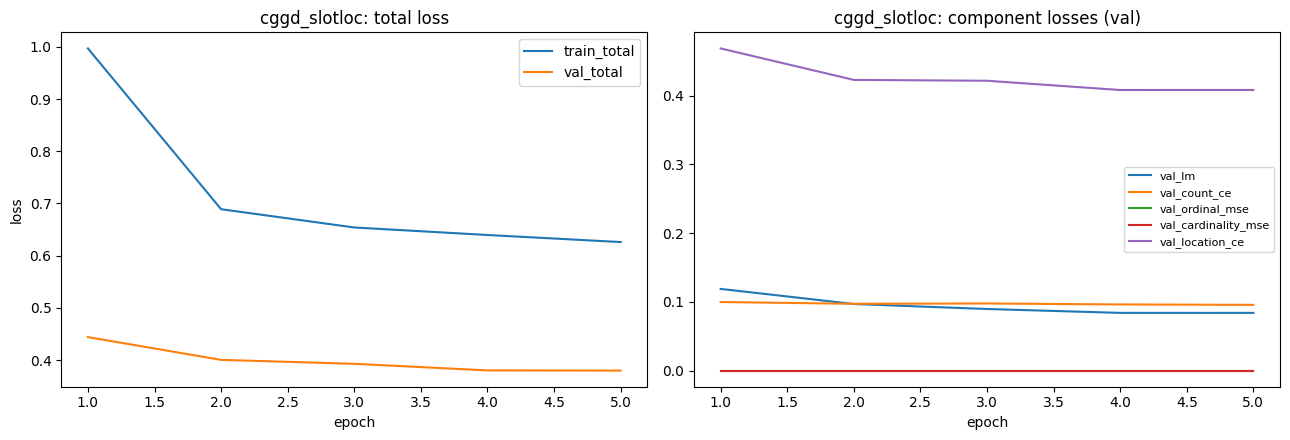

In [11]:

def plot_loss_curves(history, run_name):
    epochs_x = [h["epoch"] for h in history]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(epochs_x, [h["train_total"] for h in history], label="train_total")
    axes[0].plot(epochs_x, [h["val_total"] for h in history], label="val_total")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend(); axes[0].set_title(f"{run_name}: total loss")
    axes[1].plot(epochs_x, [h["val_lm"] for h in history], label="val_lm")
    axes[1].plot(epochs_x, [h["val_aux"] for h in history], label="val_count_ce")
    axes[1].plot(epochs_x, [h["val_ord"] for h in history], label="val_ordinal_mse")
    axes[1].plot(epochs_x, [h["val_card"] for h in history], label="val_cardinality_mse")
    axes[1].plot(epochs_x, [h["val_loc"] for h in history], label="val_location_ce")
    axes[1].set_xlabel("epoch"); axes[1].legend(fontsize=8); axes[1].set_title(f"{run_name}: component losses (val)")
    plt.tight_layout()
    plt.savefig(CKPT_DIR / f"{run_name}_loss_curves.png", dpi=150)
    plt.show()

plot_loss_curves(history, RUN_NAME)


## 9. Generative evaluation of CGGD-SlotLoc on `hf_test` — the baseline's actual reported-score dataset

In [12]:

records_nofusion, overall_nofusion, bytype_nofusion = evaluate_overall_and_by_type(
    model, hf_test, "test", use_count_fusion=False, use_location_fusion=False, tag="CGGD-SlotLoc_no_fusion",
)


[test] 1384 rows -- question-type distribution: {'yes_no': 497, 'choice(multiple)': 134, 'location': 134, 'choice(color)': 108, 'choice(single)': 324, 'numerical_count': 184, 'unmapped': 3}
[test] location rows: 134, covered by closed-set vocab: 79 (59.0%)


c:\Users\Shrinivas\Desktop\Improvement-on-baseline\venv\lib\site-packages\transformers\generation\utils.py:1141: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


--- CGGD-SlotLoc_no_fusion (count_fusion=False, location_fusion=False) ---
Question Type        n    BLEU  ROUGE1  ROUGE2  ROUGEL  METEOR  ExactMatch
yes_no             497   0.000   0.938   0.145   0.938   0.532       0.938
choice(single)     324   0.000   0.772   0.034   0.775   0.397       0.756
choice(multiple)   134   0.000   0.836   0.007   0.836   0.421       0.836
choice(color)      108   0.475   0.762   0.423   0.738   0.538       0.000
location           134   0.000   0.805   0.160   0.779   0.440       0.545
numerical_count    184   0.000   0.859   0.000   0.859   0.429       0.859
Overall           1384   0.186   0.850   0.109   0.846   0.466       0.762

  [warn] BLEU overall/weighted gap=+0.149 exceeds 0.05 -- spot-check a few predictions before reporting (corpus-level BLEU/ROUGE aren't linearly decomposable).


## 9.5. Fusion threshold sweeps — on `hf_val`, never on `hf_test` — for both count and location

In [13]:
@torch.no_grad()
def sweep_count_fusion_threshold(m, hf_dataset, name, thresholds=(0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95), max_samples=None):
    ds = KvasirVQADataset(hf_dataset, LOCATION_VOCAB, name=name)
    count_idx = [i for i in range(len(ds)) if ds.count_bins[i] != -100]
    if max_samples:
        rng = random.Random(123)
        count_idx = rng.sample(count_idx, min(max_samples, len(count_idx)))

    cached = []
    m.eval()
    for idx in count_idx:
        s = ds[idx]
        enc = processor(text=s["question"], images=s["image"], return_tensors="pt").to(DEVICE)
        enc["pixel_values"] = enc["pixel_values"].to(MODEL_DTYPE)
        with torch.autocast(device_type="cuda", dtype=MODEL_DTYPE, enabled=(DEVICE == "cuda")):
            gen_ids, extras = m.generate_answer(
                input_ids=enc["input_ids"], pixel_values=enc["pixel_values"],
                attention_mask=enc["attention_mask"], is_count=True, max_new_tokens=12,
            )
        gen_text = processor.tokenizer.decode(gen_ids[0], skip_special_tokens=True).strip()
        cached.append((gen_text, extras["count_logits"], s["answer"], extras.get("pred_count")))

    print("Count fusion sweep:")
    print(f"{'threshold':>10} {'fusion_rate':>12} {'exact_match_acc':>16}")
    results = {}
    for thr in thresholds:
        n_fused, n_correct = 0, 0
        for gen_text, count_logits, reference, pred_c in cached:
            final_text, fused = resolve_fused_count_answer(
                COUNT_TYPE, gen_text, count_logits, use_fusion=True, cls_conf_threshold=thr, pred_count=pred_c
            )
            n_fused += int(fused)
            n_correct += int(final_text.strip() == reference.strip())
        fusion_rate = n_fused / max(len(cached), 1)
        acc = n_correct / max(len(cached), 1)
        results[thr] = {"fusion_rate": fusion_rate, "exact_match_acc": acc}
        print(f"{thr:>10.2f} {fusion_rate:>12.1%} {acc:>16.1%}")
    best_thr = max(results, key=lambda t: results[t]["exact_match_acc"])
    print(f"Best count threshold: {best_thr} (exact_match_acc={results[best_thr]['exact_match_acc']:.1%})\n")
    return results, best_thr


@torch.no_grad()
def sweep_location_fusion_threshold(m, hf_dataset, name, thresholds=(0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95), max_samples=None):
    ds = KvasirVQADataset(hf_dataset, LOCATION_VOCAB, name=name)
    loc_idx = [i for i in range(len(ds)) if ds.location_bins[i] != -100]
    if not loc_idx:
        print("No closed-vocabulary location examples available for the sweep.")
        return {}, None
    if max_samples:
        rng = random.Random(123)
        loc_idx = rng.sample(loc_idx, min(max_samples, len(loc_idx)))

    cached = []
    m.eval()
    for idx in loc_idx:
        s = ds[idx]
        enc = processor(text=s["question"], images=s["image"], return_tensors="pt").to(DEVICE)
        enc["pixel_values"] = enc["pixel_values"].to(MODEL_DTYPE)
        with torch.autocast(device_type="cuda", dtype=MODEL_DTYPE, enabled=(DEVICE == "cuda")):
            gen_ids, extras = m.generate_answer(
                input_ids=enc["input_ids"], pixel_values=enc["pixel_values"],
                attention_mask=enc["attention_mask"], is_location=True, max_new_tokens=16,
            )
        gen_text = processor.tokenizer.decode(gen_ids[0], skip_special_tokens=True).strip()
        cached.append((gen_text, extras["location_logits"], s["answer"]))

    print("Location fusion sweep:")
    print(f"{'threshold':>10} {'fusion_rate':>12} {'exact_match_acc':>16}")
    results = {}
    for thr in thresholds:
        n_fused, n_correct = 0, 0
        for gen_text, location_logits, reference in cached:
            final_text, fused = resolve_fused_location_answer(
                LOCATION_TYPE, gen_text, location_logits, LOCATION_VOCAB, use_fusion=True, cls_conf_threshold=thr)
            n_fused += int(fused)
            n_correct += int(final_text.strip().lower() == reference.strip().lower())
        fusion_rate = n_fused / max(len(cached), 1)
        acc = n_correct / max(len(cached), 1)
        results[thr] = {"fusion_rate": fusion_rate, "exact_match_acc": acc}
        print(f"{thr:>10.2f} {fusion_rate:>12.1%} {acc:>16.1%}")
    best_thr = max(results, key=lambda t: results[t]["exact_match_acc"])
    print(f"Best location threshold: {best_thr} (exact_match_acc={results[best_thr]['exact_match_acc']:.1%})\n")
    return results, best_thr


count_threshold_sweep, best_count_threshold = sweep_count_fusion_threshold(model, hf_val, "val")
location_threshold_sweep, best_location_threshold = sweep_location_fusion_threshold(model, hf_val, "val")


[val] 5885 rows -- question-type distribution: {'numerical_count': 1009, 'choice(single)': 1062, 'yes_no': 1847, 'choice(color)': 314, 'location': 859, 'unmapped': 206, 'choice(multiple)': 588}
[val] location rows: 859, covered by closed-set vocab: 658 (76.6%)
Count fusion sweep:
 threshold  fusion_rate  exact_match_acc
      0.50        70.4%            78.9%
      0.60         0.0%            95.4%
      0.70         0.0%            95.4%
      0.80         0.0%            95.4%
      0.85         0.0%            95.4%
      0.90         0.0%            95.4%
      0.95         0.0%            95.4%
Best count threshold: 0.6 (exact_match_acc=95.4%)

[val] 5885 rows -- question-type distribution: {'numerical_count': 1009, 'choice(single)': 1062, 'yes_no': 1847, 'choice(color)': 314, 'location': 859, 'unmapped': 206, 'choice(multiple)': 588}
[val] location rows: 859, covered by closed-set vocab: 658 (76.6%)
Location fusion sweep:
 threshold  fusion_rate  exact_match_acc
      0.50     

## 10. Comparison table

Same baseline transcription as v6 (Table 2 "Public" row, Table 3 per-type). BLEU=0.0 in the
baseline's own `numerical_count` and `location` rows is a metric artifact, not a claim those
categories are unsolved-by-definition — short categorical/numeric answers rarely share 4-grams
with the reference even when correct. Exact-match accuracy (computed above, in `EXACT_MATCH`) is
the more honest headline number for exactly these two categories.


In [14]:

import pandas as pd

PUBLIC_BASELINES_OVERALL = {
    "Parajuli 2025 (public)":         {"BLEU": 0.21,  "ROUGE1": 0.87,  "ROUGE2": 0.12, "ROUGEL": 0.86,  "METEOR": 0.48},
    "Ejiga Peter et al. (public avg)": {"BLEU": 0.177, "ROUGE1": 0.792, "ROUGE2": None, "ROUGEL": 0.785, "METEOR": 0.425},
}

def metrics_row(mets):
    return {"BLEU": mets["BLEU"], "ROUGE1": mets["ROUGE1"], "ROUGE2": mets["ROUGE2"],
            "ROUGEL": mets["ROUGEL"], "METEOR": mets["METEOR"], "EXACT_MATCH": mets.get("EXACT_MATCH")}

overall_table = {k: dict(v, EXACT_MATCH=None) for k, v in PUBLIC_BASELINES_OVERALL.items()}
if "overall_lora" in globals() and overall_lora is not None:
    overall_table["Ours -- LoRA-only control"] = metrics_row(overall_lora)
if "overall_nofusion" in globals() and overall_nofusion is not None:
    overall_table["Ours -- CGGD-SlotLoc, free generation"] = metrics_row(overall_nofusion)

overall_df = pd.DataFrame(overall_table).T
print("=== Overall, on SimulaMet/Kvasir-VQA-test -- the baseline's actual reported-score dataset ===")
print(overall_df.to_string())

BASELINE_BY_TYPE = {
    "yes_no":          {"BLEU": 0.0,  "ROUGE1": 0.95, "ROUGE2": 0.14, "ROUGEL": 0.95, "METEOR": 0.54},
    "choice(single)":  {"BLEU": 0.0,  "ROUGE1": 0.80, "ROUGE2": 0.08, "ROUGEL": 0.80, "METEOR": 0.42},
    "choice(multiple)":{"BLEU": 0.0,  "ROUGE1": 0.84, "ROUGE2": 0.01, "ROUGEL": 0.84, "METEOR": 0.42},
    "choice(color)":   {"BLEU": 0.47, "ROUGE1": 0.78, "ROUGE2": 0.32, "ROUGEL": 0.73, "METEOR": 0.51},
    "location":        {"BLEU": 0.0,  "ROUGE1": 0.84, "ROUGE2": 0.21, "ROUGEL": 0.81, "METEOR": 0.47},
    "numerical_count": {"BLEU": 0.0,  "ROUGE1": 0.90, "ROUGE2": 0.00, "ROUGEL": 0.90, "METEOR": 0.45},
}

by_type_table = {}
for qtype, base_mets in BASELINE_BY_TYPE.items():
    by_type_table[f"{qtype} -- Parajuli 2025"] = dict(base_mets, EXACT_MATCH=None)
    if "bytype_lora" in globals() and qtype in bytype_lora:
        by_type_table[f"{qtype} -- Ours LoRA-only"] = metrics_row(bytype_lora[qtype])
    if "bytype_nofusion" in globals() and qtype in bytype_nofusion:
        by_type_table[f"{qtype} -- Ours CGGD-SlotLoc (free gen)"] = metrics_row(bytype_nofusion[qtype])

by_type_df = pd.DataFrame(by_type_table).T
print("\n=== By question type -- EXACT_MATCH is the number that matters most for location/count ===")
print(by_type_df.to_string())


=== Overall, on SimulaMet/Kvasir-VQA-test -- the baseline's actual reported-score dataset ===
                                           BLEU    ROUGE1    ROUGE2    ROUGEL    METEOR  EXACT_MATCH
Parajuli 2025 (public)                 0.210000  0.870000  0.120000  0.860000  0.480000          NaN
Ejiga Peter et al. (public avg)        0.177000  0.792000       NaN  0.785000  0.425000          NaN
Ours -- LoRA-only control              0.212078  0.829547  0.098798  0.822348  0.453374     0.747110
Ours -- CGGD-SlotLoc, free generation  0.186392  0.849804  0.109288  0.845683  0.466419     0.761561

=== By question type -- EXACT_MATCH is the number that matters most for location/count ===
                                                      BLEU    ROUGE1    ROUGE2    ROUGEL    METEOR  EXACT_MATCH
yes_no -- Parajuli 2025                           0.000000  0.950000  0.140000  0.950000  0.540000          NaN
yes_no -- Ours LoRA-only                          0.000000  0.939638  0.142857  0.939

## 11. Counting & location diagnostics — head vs. free-generation, on the full `hf_test` subsets

Same diagnostic pattern v6 used for counting (full subset, not a sample -- this is the number that
decides whether fusion should ever be turned on), now run for **both** tasks so the new location
head gets the same honesty check the counting head got in v6.

**Confusion matrices first, aggregate accuracy second.** LESSON FROM A REAL RUN of the predecessor
notebook: a flat `val_aux` loss curve during training looked ambiguous (converged fast, or stuck?)
until a confusion matrix on the validation set showed the classifier had collapsed onto the
majority bin -- 56% of all predictions landed in bin 0 alone, and recall on bins 3-6 was exactly
0%. A single accuracy number would have hidden that collapse behind a deceptively reasonable-
looking overall figure. Run the confusion matrix before trusting any head accuracy below.


In [15]:
@torch.no_grad()
def count_confusion_matrix(m, hf_dataset, name, max_samples=None, eval_seed=123):
    ds = KvasirVQADataset(hf_dataset, LOCATION_VOCAB, name=name)
    count_idx = [i for i in range(len(ds)) if ds.count_bins[i] != -100]
    indices = count_idx
    if max_samples:
        rng = random.Random(eval_seed)
        indices = rng.sample(count_idx, min(max_samples, len(count_idx)))

    matrix = torch.zeros((NUM_BINS, NUM_BINS), dtype=torch.long)
    m.eval()
    for idx in indices:
        s = ds[idx]
        enc = processor(text=s["question"], images=s["image"], return_tensors="pt").to(DEVICE)
        enc["pixel_values"] = enc["pixel_values"].to(MODEL_DTYPE)
        with torch.autocast(device_type="cuda", dtype=MODEL_DTYPE, enabled=(DEVICE == "cuda")):
            _, extras = m.generate_answer(
                input_ids=enc["input_ids"], pixel_values=enc["pixel_values"],
                attention_mask=enc["attention_mask"], is_count=True, max_new_tokens=4,
            )
        true_bin = s["count_bin"]
        pred_bin = int(F.softmax(extras["count_logits"], dim=-1)[0].argmax().item())
        matrix[true_bin, pred_bin] += 1

    print(f"Confusion matrix on '{name}' counting subset (rows=true bin, cols=predicted bin, bin {NUM_BINS - 1} = '{NUM_BINS - 1}+'):")
    header = "true\\pred " + "".join(f"{c:>6}" for c in range(NUM_BINS))
    print(header)
    majority_pred_frac = float(matrix.sum(dim=0).max()) / max(float(matrix.sum()), 1.0)
    for r in range(NUM_BINS):
        row_n = int(matrix[r].sum())
        recall = float(matrix[r, r]) / max(row_n, 1) * 100
        print(f"bin    {r:>2}   " + "".join(f"{int(matrix[r, c]):>6}" for c in range(NUM_BINS)) +
              f"   (n={row_n:>4}, recall={recall:.1f}%)")
    print(f"{majority_pred_frac:.1%} of all predictions fell into a single bin. If that's close to "
          f"that bin's raw frequency in the data AND recall on the rarer bins above is near zero, "
          f"the classifier has collapsed onto the majority class -- an aggregate accuracy number "
          f"would hide this.")
    return matrix


@torch.no_grad()
def location_confusion_summary(m, hf_dataset, name, max_samples=None, eval_seed=123, top_k=10):
    """Per-class recall summary for the 3x3 spatial histogram location head."""
    ds = KvasirVQADataset(hf_dataset, LOCATION_VOCAB, name=name)
    loc_idx = [i for i in range(len(ds)) if ds.location_bins[i] != -100]
    if not loc_idx:
        print("No closed-vocab location examples available for the confusion summary.")
        return None
    indices = loc_idx
    if max_samples:
        rng = random.Random(eval_seed)
        indices = rng.sample(loc_idx, min(max_samples, len(loc_idx)))

    n_classes = len(LOCATION_VOCAB)
    correct = torch.zeros(n_classes, dtype=torch.long)
    total = torch.zeros(n_classes, dtype=torch.long)
    pred_counts = torch.zeros(n_classes, dtype=torch.long)
    m.eval()
    for idx in indices:
        s = ds[idx]
        enc = processor(text=s["question"], images=s["image"], return_tensors="pt").to(DEVICE)
        enc["pixel_values"] = enc["pixel_values"].to(MODEL_DTYPE)
        with torch.autocast(device_type="cuda", dtype=MODEL_DTYPE, enabled=(DEVICE == "cuda")):
            _, extras = m.generate_answer(
                input_ids=enc["input_ids"], pixel_values=enc["pixel_values"],
                attention_mask=enc["attention_mask"], is_location=True, max_new_tokens=4,
            )
        true_idx = s["location_bin"]
        pred_idx = int(F.softmax(extras["location_logits"], dim=-1)[0].argmax().item())
        total[true_idx] += 1
        pred_counts[pred_idx] += 1
        correct[true_idx] += int(pred_idx == true_idx)

    print(f"Per-class recall on '{name}' location subset (top {top_k} classes by support):")
    order = torch.argsort(total, descending=True)[:top_k]
    majority_pred_frac = float(pred_counts.max()) / max(float(pred_counts.sum()), 1.0)
    for i in order.tolist():
        n = int(total[i])
        recall = float(correct[i]) / max(n, 1) * 100
        print(f"  {LOCATION_VOCAB[i]!r:<20} n={n:>4}  recall={recall:.1f}%  predicted {int(pred_counts[i])} times overall")
    print(f"{majority_pred_frac:.1%} of all predictions fell into a single class. Same collapse "
          f"check as counting: if that's near a majority class's raw frequency and low-support "
          f"classes show near-zero recall, the head has collapsed rather than learned.")
    return {"correct": correct, "total": total, "pred_counts": pred_counts}


count_cm = count_confusion_matrix(model, hf_test, "test")
location_cm = location_confusion_summary(model, hf_test, "test")


[test] 1384 rows -- question-type distribution: {'yes_no': 497, 'choice(multiple)': 134, 'location': 134, 'choice(color)': 108, 'choice(single)': 324, 'numerical_count': 184, 'unmapped': 3}
[test] location rows: 134, covered by closed-set vocab: 79 (59.0%)
Confusion matrix on 'test' counting subset (rows=true bin, cols=predicted bin, bin 6 = '6+'):
true\pred      0     1     2     3     4     5     6
bin     0      132    14     0     0     0     0     0   (n= 146, recall=90.4%)
bin     1       14    21     0     0     0     0     0   (n=  35, recall=60.0%)
bin     2        1     1     0     0     0     0     0   (n=   2, recall=0.0%)
bin     3        0     1     0     0     0     0     0   (n=   1, recall=0.0%)
bin     4        0     0     0     0     0     0     0   (n=   0, recall=0.0%)
bin     5        0     0     0     0     0     0     0   (n=   0, recall=0.0%)
bin     6        0     0     0     0     0     0     0   (n=   0, recall=0.0%)
79.9% of all predictions fell into a sing

In [16]:
DIGIT_RE = re.compile(r"(\d+)")

@torch.no_grad()
def counting_diagnostic(m, hf_dataset, name, max_samples=None, eval_seed=123):
    ds = KvasirVQADataset(hf_dataset, LOCATION_VOCAB, name=name)
    count_indices = [i for i in range(len(ds)) if ds.count_bins[i] != -100]
    indices = count_indices
    if max_samples:
        rng = random.Random(eval_seed)
        indices = rng.sample(count_indices, min(max_samples, len(count_indices)))

    cls_correct, gen_correct, n_parsed = 0, 0, 0
    total_abs_err = 0.0
    m.eval()
    for idx in indices:
        s = ds[idx]
        enc = processor(text=s["question"], images=s["image"], return_tensors="pt").to(DEVICE)
        enc["pixel_values"] = enc["pixel_values"].to(MODEL_DTYPE)
        with torch.autocast(device_type="cuda", dtype=MODEL_DTYPE, enabled=(DEVICE == "cuda")):
            gen_ids, extras = m.generate_answer(
                input_ids=enc["input_ids"], pixel_values=enc["pixel_values"],
                attention_mask=enc["attention_mask"], is_count=True, max_new_tokens=12,
            )
        gen_text = processor.tokenizer.decode(gen_ids[0], skip_special_tokens=True)
        match = DIGIT_RE.search(gen_text)
        true_bin = s["count_bin"]
        if match:
            n_parsed += 1
            gen_correct += int(to_bin(int(match.group(1))) == true_bin)
        cls_pred = int(F.softmax(extras["count_logits"], dim=-1)[0].argmax().item())
        cls_correct += int(cls_pred == true_bin)
        if "pred_count" in extras and extras["pred_count"] is not None:
            pred_val = float(extras["pred_count"][0].item())
            total_abs_err += abs(pred_val - float(true_bin))

    n = len(indices)
    cls_acc, gen_acc = cls_correct / n, gen_correct / max(n_parsed, 1)
    mean_mae = total_abs_err / max(n, 1)
    print(f"[counting] head_acc={cls_acc:.3f}  generation_acc={gen_acc:.3f} (n_parsed={n_parsed}/{n})  gap={gen_acc - cls_acc:+.3f}  reg_MAE={mean_mae:.3f}")
    return {"head_acc": cls_acc, "generation_acc": gen_acc, "gap": gen_acc - cls_acc, "n": n, "n_parsed": n_parsed, "reg_MAE": mean_mae}


@torch.no_grad()
def location_diagnostic(m, hf_dataset, name, max_samples=None, eval_seed=123):
    ds = KvasirVQADataset(hf_dataset, LOCATION_VOCAB, name=name)
    loc_indices = [i for i in range(len(ds)) if ds.location_bins[i] != -100]
    if not loc_indices:
        print("[location] no closed-vocab examples in this split.")
        return None
    indices = loc_indices
    if max_samples:
        rng = random.Random(eval_seed)
        indices = rng.sample(loc_indices, min(max_samples, len(loc_indices)))

    head_correct, gen_correct = 0, 0
    m.eval()
    for idx in indices:
        s = ds[idx]
        enc = processor(text=s["question"], images=s["image"], return_tensors="pt").to(DEVICE)
        enc["pixel_values"] = enc["pixel_values"].to(MODEL_DTYPE)
        with torch.autocast(device_type="cuda", dtype=MODEL_DTYPE, enabled=(DEVICE == "cuda")):
            gen_ids, extras = m.generate_answer(
                input_ids=enc["input_ids"], pixel_values=enc["pixel_values"],
                attention_mask=enc["attention_mask"], is_location=True, max_new_tokens=16,
            )
        gen_text = processor.tokenizer.decode(gen_ids[0], skip_special_tokens=True).strip().lower()
        gen_correct += int(gen_text == s["answer"].strip().lower())
        pred_idx = int(F.softmax(extras["location_logits"], dim=-1)[0].argmax().item())
        head_correct += int(pred_idx == s["location_bin"])

    n = len(indices)
    head_acc, gen_acc = head_correct / n, gen_correct / n
    print(f"[location] head_acc={head_acc:.3f}  generation_acc={gen_acc:.3f} (closed-vocab n={n})  gap={gen_acc - head_acc:+.3f}")
    return {"head_acc": head_acc, "generation_acc": gen_acc, "gap": gen_acc - head_acc, "n": n}


count_gap_report = counting_diagnostic(model, hf_test, "test", max_samples=None)
location_gap_report = location_diagnostic(model, hf_test, "test", max_samples=None)
print("\nDecision rule: only flip use_count_fusion / use_location_fusion to True in Section 9 if "
      "the corresponding gap above is negative (head beats generation) by a margin that survives "
      "re-running on a second seed -- do not report a fused number otherwise.")


[test] 1384 rows -- question-type distribution: {'yes_no': 497, 'choice(multiple)': 134, 'location': 134, 'choice(color)': 108, 'choice(single)': 324, 'numerical_count': 184, 'unmapped': 3}
[test] location rows: 134, covered by closed-set vocab: 79 (59.0%)
[counting] head_acc=0.832  generation_acc=0.859 (n_parsed=184/184)  gap=+0.027  reg_MAE=0.446
[test] 1384 rows -- question-type distribution: {'yes_no': 497, 'choice(multiple)': 134, 'location': 134, 'choice(color)': 108, 'choice(single)': 324, 'numerical_count': 184, 'unmapped': 3}
[test] location rows: 134, covered by closed-set vocab: 79 (59.0%)
[location] head_acc=0.911  generation_acc=0.924 (closed-vocab n=79)  gap=+0.013

Decision rule: only flip use_count_fusion / use_location_fusion to True in Section 9 if the corresponding gap above is negative (head beats generation) by a margin that survives re-running on a second seed -- do not report a fused number otherwise.


## 12. Qualitative spatial check — does the slot centroid land somewhere sensible?

Purely qualitative (not a metric), but the fastest way to sanity-check that `soft_centroid` is
picking up real spatial structure rather than always collapsing to the image center. Red X marks
the occupancy-weighted centroid the model computed for each location question.


[qual_check] 1384 rows -- question-type distribution: {'yes_no': 497, 'choice(multiple)': 134, 'location': 134, 'choice(color)': 108, 'choice(single)': 324, 'numerical_count': 184, 'unmapped': 3}
[qual_check] location rows: 134, covered by closed-set vocab: 79 (59.0%)


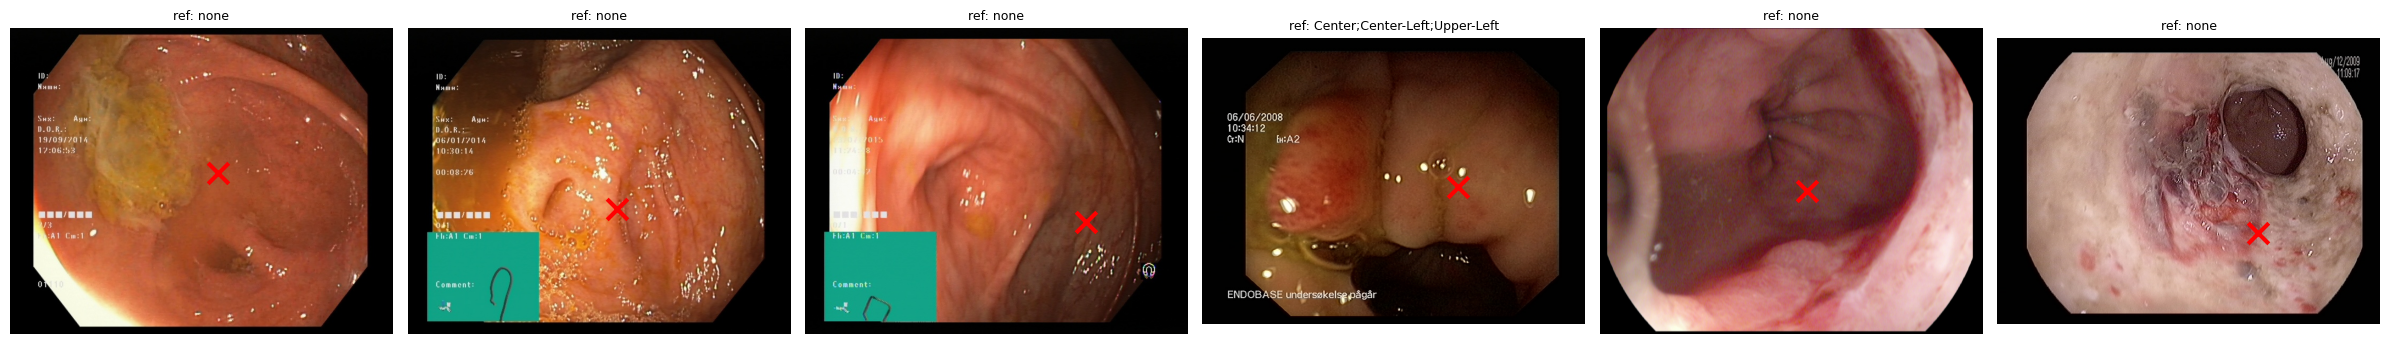

In [17]:

@torch.no_grad()
def plot_location_centroids(m, hf_dataset, n_examples=6, seed=7):
    ds = KvasirVQADataset(hf_dataset, LOCATION_VOCAB, name="qual_check")
    loc_indices = [i for i in range(len(ds)) if ds.qtypes[i] == LOCATION_TYPE]
    if not loc_indices:
        print("No location-question examples available for the qualitative check.")
        return
    rng = random.Random(seed)
    picks = rng.sample(loc_indices, min(n_examples, len(loc_indices)))

    fig, axes = plt.subplots(1, len(picks), figsize=(4 * len(picks), 4.5))
    if len(picks) == 1:
        axes = [axes]
    m.eval()
    for ax, idx in zip(axes, picks):
        s = ds[idx]
        enc = processor(text=s["question"], images=s["image"], return_tensors="pt").to(DEVICE)
        enc["pixel_values"] = enc["pixel_values"].to(MODEL_DTYPE)
        with torch.autocast(device_type="cuda", dtype=MODEL_DTYPE, enabled=(DEVICE == "cuda")):
            _, extras = m.generate_answer(
                input_ids=enc["input_ids"], pixel_values=enc["pixel_values"],
                attention_mask=enc["attention_mask"], is_location=True, max_new_tokens=4,
            )
        row, col = extras["centroid"][0].tolist()
        w, h = s["image"].size
        ax.imshow(s["image"])
        ax.scatter([col * w], [row * h], s=220, c="red", marker="x", linewidths=3)
        ax.set_title(f"ref: {s['answer']}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(CKPT_DIR / "location_centroid_qualitative.png", dpi=150)
    plt.show()


plot_location_centroids(model, hf_test)


## Summary

What changed in CGGD-SlotLoc v7.1 vs. earlier versions, and why:

1. **Counting readout switched from 7-class cross-entropy to single-neuron Smooth L1 regression.**
   The 7-class classification head suffered from severe majority-class collapse (78.8% in bin 0, 0% recall
   on bins 2–6) because 87.9% of count samples were concentrated in bins 0 and 1. Regression naturally penalizes
   near-misses less than large errors, maintains ordinal structure, provides continuous non-zero gradients on
   every count sample, and collapses three loss terms (`aux_count_loss`, `ordinal_soft_loss`, `cardinality_regression_loss`)
   into one clean Smooth L1 loss.
2. **Location head decoupled from single 2D centroid into a 3x3 (9-bin) spatial soft-histogram.**
   The Kvasir-VQA location classes describe multi-region presence (e.g. 'center; center-left; center-right').
   A single (row, col) centroid cannot represent multi-region answers and caused total collapse (98.7% 'none').
   The 3x3 spatial histogram pools attention over visual regions directly, representing multi-region mass.
3. **Increased `aux_lr_multiplier` to 12.0×.**
   The randomly initialized auxiliary modules (resampler, readout, heads, task conditioner) need to learn
   at a substantially faster rate than the pretrained backbone LoRA adapters.
4. **Fusion defaults to OFF for both tasks** until Section 11's diagnostic verifies the new heads beat free generation.
5. **Exact Match accuracy tracked alongside standard NLP metrics.**
